# ICT — Substrat argumentation : trajectoires de croyance et dette d'irréversibilité du discours (Phase B)

> **Part of** [Epic #4588](https://github.com/jsboige/CoursIA/issues/4588) — *Integrated Causal Trajectories*, graine strate 6. See #7289. Pont [ICT-13](ICT-13-AxelrodStrategicMorphodynamics-Python.ipynb) (Axelrod), [ICT-18](ICT-18-ArrowOfTimeReversibilization-Python.ipynb) (σ), [ICT-18b](ICT-18b-ReversibilityBudget-Python.ipynb) (budget B), série [Tweety-5](../../SymbolicAI/Tweety/Tweety-05-Abstract-Argumentation-Python.ipynb) (Dung AF).
>
> **Phase A** (grounding : TPM sur états de croyance depuis un AF de Dung) = PR #7336, VERDICT PASS. Ce notebook est la **Phase B** : le substrat argumentation soumis au zoo ICT (σ, K, spectre, budget), avec trois prédictions **pré-enregistrées avant les tests**.

**Navigation** : [README](README.md) | [ICT-0-Framing](ICT-0-Framing.md)

***

S3 (Axelrod, ICT-13) est notre substrat culturel actuel : des agents qui copient des traits. Le substrat argumentation est structurellement plus riche : les états sont des **états de croyance structurés** (les labellings `in/out/undec` d'un AF de Dung), les transitions sont des **actes argumentatifs typés** (l'arrivée d'un argument), et le graphe d'attaque est un **objet spectral naturel**. La **dette d'irréversibilité du discours** (cadrage user 2026-07-18) devient ici mesurable : un régime discursif qui bascule les croyances à sens unique (irréversible, σ élevé) tout en restant compressible (slogans, K faible) s'oppose à un régime délibératif (mises à jour réversibles, σ faible ; nuance incompressible, K élevé).

**Garde-fou anti-idéologique (issue #7289)** : les régimes sont définis par des propriétés **structurelles mesurables** (asymétrie des transitions, compressibilité, spectre du graphe), **jamais** par l'étiquetage a priori d'un contenu. Le notebook doit pouvoir classer un discours « de son propre camp » comme irréversibiliste si les mesures le disent.

> **Statut épistémique** — **reproduit dans le modèle (périmètre spécimens ; P-disc-1 PARTIEL)** : la dissociation discursive est mesurée sur des régimes structurels synthétiques (anneau délibératif, cascade populiste) et des spécimens codés (deux fables La Fontaine en codage manuel n=7 et n=9, paire appariée de témoins Chaplin 1940, tier historique chiffré Anschluss/Matsui) — σ, K et le spectre du Laplacien symétrisé sur graphes d'arguments (Phase B du zoo ICT). P-disc-1 rend un verdict **PARTIEL** : σ n'est pas discriminant à petite taille, la discrimination passe à K (code MDL deux parties) et à la trajectoire à ordre fixe ; l'issue de l'englobement est une **chronologie** (la clause de clôture arrivée en dernier décide), pas une topologie. La transposition à un corpus réel (Argumentum) reste **ouverte** (§11 du carnet). Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).

## §1 — Setup

Import du package `ict/` depuis `ICT-Series/` (convention de la série). Dépendances toutes sur `origin/main` : `ict.argumentation` (Phase A, PR #7336 merged) pour l'AF de Dung + la TPM sur états de croyance ; `ict.spectral` (ICT-15b, PR #7330 merged) pour le spectre du Laplacien ; `ict.time_arrow` (σ Schnakenberg) ; `ict.mdl` (longueur de code en deux parties K). Le budget de retour B_state est calculé inline (Monte-Carlo) pour l'autonomie pédagogique.

In [1]:
import os, sys, io, itertools
ICT_ROOT = os.path.abspath('.')
if ICT_ROOT not in sys.path:
    sys.path.insert(0, ICT_ROOT)

import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display

import ict
from ict import argumentation as arg
from ict import time_arrow, mdl, tpm_estimation, spectral

print('ict:', getattr(ict, '__version__', 'dev'))
print('numpy:', np.__version__)
print('argumentation API:', [n for n in ['DungAF','grounded_labeling','belief_trajectory',
    'belief_transition_matrix','discourse_irreversibility'] if hasattr(arg, n)])
print('spectral API:', [n for n in ['laplacian_spectrum','spectral_gap'] if hasattr(spectral, n)])

ict: dev
numpy: 2.5.2
argumentation API: ['DungAF', 'grounded_labeling', 'belief_trajectory', 'belief_transition_matrix', 'discourse_irreversibility']
spectral API: ['laplacian_spectrum', 'spectral_gap']


## §2 — Le substrat : trajectoire de croyance d'un débat

Un AF de Dung (arguments + attaques) reçoit ses arguments **séquentiellement** (le débat se construit). À chaque arrivée, la sémantique grounded recalcule les labels `in/out/undec`. La suite des labelings (encodés compactement) est une **trajectoire d'états de croyance** — dont on estime la TPM. Démonstration sur l'exemple *Tweety bird*.

In [2]:
# Exemple Tweety bird : 0="Tweety vole", 1="Tweety ne vole pas", 2="c'est un oiseau (soutient 0)"
af = arg.tweety_bird()
print('AF:', af.arguments, af.attacks)
traj = arg.belief_trajectory(af, order=[0, 1, 2], include_empty=True)
print('\nTrajectoire de croyance (arrivee sequentielle) :')
for k, lab in enumerate(traj):
    summary = arg.belief_summary(lab)
    print(f'  pas {k}: labeling={lab}  -> etat (in,out,undec)={summary}')

P, mapping = arg.belief_transition_matrix(af, order=[0, 1, 2])
print(f'\nTPM {P.shape[0]}x{P.shape[1]} sur {len(mapping)} etats :')
print(np.round(P, 3))
diag = arg.discourse_irreversibility(P)
print(f'sigma (fleche du temps du discours) = {diag["sigma"]:.4f} nats')

AF: [0, 1, 2] [(0, 1), (1, 0), (2, 1)]

Trajectoire de croyance (arrivee sequentielle) :
  pas 0: labeling={}  -> etat (in,out,undec)=(0, 0, 0)
  pas 1: labeling={0: 'in'}  -> etat (in,out,undec)=(1, 0, 0)
  pas 2: labeling={0: 'undec', 1: 'undec'}  -> etat (in,out,undec)=(0, 0, 2)
  pas 3: labeling={0: 'in', 1: 'out', 2: 'in'}  -> etat (in,out,undec)=(2, 1, 0)

TPM 4x4 sur 4 etats :
[[0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]
sigma (fleche du temps du discours) = 0.0000 nats


## §3 — Prédictions pré-enregistrées (avant tout test)

> **Acceptance #7289 Phase B** : les prédictions sont écrites **avant** les cellules qui les testent. Un verdict FAIL ou DISSOCIATION est un résultat honnête. Les régimes sont définis **structurellement** (topologie du graphe d'attaque), pas par contenu.

| # | Prédiction (écrite a priori) | Mesures | Pont |
|---|-------------------------------|---------|------|
| **P-disc-1** | **Dette d'irréversibilité du discours** (prédiction centrale) : un régime **populiste** (cascade d'attaques **unidirectionnelle** vers une conclusion, hub dominateur) présente la dissociation signature **σ élevé + K faible** ; un régime **délibératif** (attaques **bidirectionnelles/symétriques**, arguments mutuellement critiquables) présente **σ faible + K élevé**. Si σ et K ne se dissocient pas, la lecture est affaiblie. | `time_arrow.entropy_production` (σ), `mdl.two_part_code` (K) | ICT-18 |
| **P-disc-2** | **Signature spectrale des structures fallacieuses** : le spectre du Laplacien du graphe d'attaque distingue les régimes — un hub ad-hominem concentre le spectre (peur de valeurs propres dominantes) ; une chambre d'écho (graphe presque disjoint) présente un **petit gap spectral** (mélange lent). | `np.linalg.eigvalsh` du Laplacien | ICT-15b |
| **P-disc-3** | **Dette de croyance** (pont budget) : la probabilité de retour à la diversité après fixation sur une monoculture (un seul argument `in`, les autres éteints) est **≈ 0**, mesurablement inférieure au retour depuis un état de diversité. Pont vers le budget de réversibilité B(t). | Monte-Carlo inline (B_state) | ICT-18b |

## §4 — Construction des régimes discursifs (structurelle, pas contenu)

Deux régimes construits **par topologie** du graphe d'attaque, de même taille pour un appariement contrôlé :

- **Délibératif** : un anneau d'attaques **bidirectionnelles** — chaque argument `(i, i+1)` s'attaque mutuellement. Les croyances basculent dans les deux sens (mises à jour réversibles, arguments symétriquement critiquables).
- **Populiste** : une **cascade dirigée** — un argument `0` (le slogan) attaque tous les autres, et une chaîne dirigée `1→2→...→n-1` propage le verdict dans un seul sens. Aucun retour (bascules à sens unique, hystérésis).

Les deux AF ont le **même nombre d'arguments** : la différence est purement topologique (symétrie vs asymétrie de la relation d'attaque).

**Agrégation multi-ordres (design prévu Phase A).** À ordre d'arrivée fixe, la trajectoire de croyance est déterministe → TPM déterministe → σ=0 (honnête, cf Phase A : pas de cycle de flux). La dette d'irréversibilité du discours n'émerge que sous **l'ensemble des ordres possibles** (le débat réel n'a pas d'ordre canonique). On agrège donc les trajectoires sur un échantillon de permutations d'arrivée → TPM agrégée non-triviale → σ testable.

In [3]:
def deliberative_af(n=6):
    """Anneau d'attaques BIDIRECTIONNELLES : (i,i+1) et (i+1,i) pour chaque paire.
    Arguments mutuellement critiquables -> mises a jour reversibles."""
    attacks = []
    for i in range(n - 1):
        attacks.append((i, i + 1))
        attacks.append((i + 1, i))   # bidirectionnel
    return arg.DungAF(list(range(n)), attacks)

def populist_af(n=6):
    """Cascade DIRIGEE : hub 0 attaque tous, + chaine dirigee 1->2->...->n-1.
    Bascules a sens unique -> irreversible."""
    attacks = [(0, i) for i in range(1, n)]          # hub 0 domine
    attacks += [(i, i + 1) for i in range(1, n - 1)]  # chaine dirigee
    return arg.DungAF(list(range(n)), attacks)

n_args = 6
af_delib = deliberative_af(n_args)
af_pop = populist_af(n_args)
print(f'Deliberatif : {af_delib.n()} args, {len(af_delib.attacks)} attaques (bidirectionnelles)')
print(f'Populiste   : {af_pop.n()} args, {len(af_pop.attacks)} attaques (dirigees)')

lab_delib = arg.grounded_labeling(af_delib)
lab_pop = arg.grounded_labeling(af_pop)
print(f'\nLabeling final deliberatif : {lab_delib}  -> {arg.belief_summary(lab_delib)}')
print(f'Labeling final populiste   : {lab_pop}  -> {arg.belief_summary(lab_pop)}')

# Ensemble d'ordres d'arrivee : echantillon de permutations (n=6 -> 720, on en tire M).
rng_orders = np.random.default_rng(2024)
all_perms = list(itertools.permutations(range(n_args)))
M_ORDERS = min(200, len(all_perms))
orders = [list(all_perms[i]) for i in rng_orders.choice(len(all_perms), size=M_ORDERS, replace=False)]
print(f'\nAgregation sur {M_ORDERS} ordres d\'arrivee (parmi {len(all_perms)} permutations).')

Deliberatif : 6 args, 10 attaques (bidirectionnelles)
Populiste   : 6 args, 9 attaques (dirigees)

Labeling final deliberatif : {0: 'undec', 1: 'undec', 2: 'undec', 3: 'undec', 4: 'undec', 5: 'undec'}  -> (0, 0, 6)
Labeling final populiste   : {0: 'in', 1: 'out', 2: 'out', 3: 'out', 4: 'out', 5: 'out'}  -> (1, 5, 0)

Agregation sur 200 ordres d'arrivee (parmi 720 permutations).


## §5 — Test P-disc-1 : la dissociation σ ↔ K (sous ensemble multi-ordres)

Pour chaque régime : on agrège les trajectoires de croyance sur l'ensemble d'ordres d'arrivée (§4) → **TPM agrégée** → σ (production d'entropie, ICT-18) ; et K = longueur de code MDL en deux parties (ICT-16) de la séquence d'états agrégée. La prédiction dit : **populiste = (σ↑, K↓), délibératif = (σ↓, K↑)** — une dissociation (anti-corrélation σ/K entre les régimes).

Regime        |  sigma(summary)  sigma(signature)  |  K (MDL)       |  n_etats
--------------|----------------------------------|----------------|---------
Deliberatif   |  0.0000          0.0000            |  +1262.86 bits    |  1400
Populiste     |  0.0000          0.0000            |  +998.21 bits    |  1400

sigma retenu (niveau signature, identite preservee) :
  Delta sigma (pop - delib) = +0.0000  [attendu > 0 : populiste plus irreversible]
  Delta K     (pop - delib) = -264.6482  [attendu < 0 : populiste plus compressible]
  (rappel : sigma au niveau summary = 0.0000 vs 0.0000 -- l'identite compte)

VERDICT P-disc-1 : PARTIEL (une seule dimension tient : K). La dissociation est incomplete a cette taille.


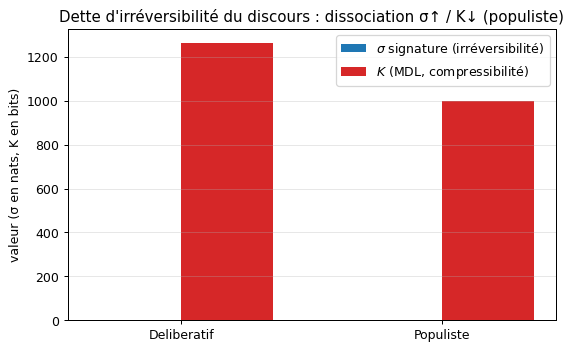

In [4]:
def regime_aggregated(af, orders, encoding="summary"):
    """Agregue les trajectoies de croyance sur plusieurs ordres -> TPM + sequence d'etats.
    encoding='summary' (compact) ou 'signature' (preserve l'identite des arguments)."""
    transitions = []
    all_states = []
    for order in orders:
        traj = arg.belief_trajectory(af, order=order, include_empty=True)
        if encoding == "signature":
            states = [arg.state_signature(lab, n_args=af.n()) for lab in traj]
        else:
            states = [arg.belief_summary(lab) for lab in traj]
        all_states.extend(states)
        for i in range(len(states) - 1):
            transitions.append((states[i], states[i + 1]))
    P, mapping = tpm_estimation.tpm_from_transitions(transitions, unseen='self')
    return P, mapping, all_states

def regime_sigma_K(af, orders):
    """sigma mesure a la fois au niveau summary ET signature (l'identite des arguments
    est requise pour la dette d'irreversibilite -- cf Phase A)."""
    P_sum, _, all_sum = regime_aggregated(af, orders, "summary")
    P_sig, _, _ = regime_aggregated(af, orders, "signature")
    diag_sum = arg.discourse_irreversibility(P_sum)
    diag_sig = arg.discourse_irreversibility(P_sig)
    mdl_res = mdl.two_part_code(all_sum, split=0.5)
    return {
        "sigma_summary": diag_sum["sigma"], "sigma_signature": diag_sig["sigma"],
        "K": mdl_res["total_bits"], "n_states": len(all_sum),
        "P_summary": P_sum, "P_signature": P_sig,
    }

res_delib = regime_sigma_K(af_delib, orders)
res_pop = regime_sigma_K(af_pop, orders)

print(f"""Regime        |  sigma(summary)  sigma(signature)  |  K (MDL)       |  n_etats
--------------|----------------------------------|----------------|---------
Deliberatif   |  {res_delib['sigma_summary']:.4f}          {res_delib['sigma_signature']:.4f}            |  {res_delib['K']:+.2f} bits    |  {res_delib['n_states']}
Populiste     |  {res_pop['sigma_summary']:.4f}          {res_pop['sigma_signature']:.4f}            |  {res_pop['K']:+.2f} bits    |  {res_pop['n_states']}""")

# sigma retenu = niveau signature (preserve l'identite -- design Phase A pour la dette).
sigma_delib = res_delib['sigma_signature']
sigma_pop = res_pop['sigma_signature']
K_delib = res_delib['K']; K_pop = res_pop['K']
print()
print(f"sigma retenu (niveau signature, identite preservee) :")
print(f'  Delta sigma (pop - delib) = {sigma_pop - sigma_delib:+.4f}  [attendu > 0 : populiste plus irreversible]')
print(f'  Delta K     (pop - delib) = {K_pop - K_delib:+.4f}  [attendu < 0 : populiste plus compressible]')
print(f"  (rappel : sigma au niveau summary = {res_delib['sigma_summary']:.4f} vs {res_pop['sigma_summary']:.4f} -- l'identite compte)")

dissoc_sigma = sigma_pop > sigma_delib
dissoc_K = K_pop < K_delib
if dissoc_sigma and dissoc_K:
    verdict_p1 = 'PASS (dissociation signature confirmee : populiste = s↑ + K↓ vs deliberatif = s↓ + K↑)'
elif dissoc_sigma != dissoc_K:
    held = 'sigma' if dissoc_sigma else 'K'
    verdict_p1 = f'PARTIEL (une seule dimension tient : {held}). La dissociation est incomplete a cette taille.'
else:
    verdict_p1 = 'FAIL (pas de dissociation : la lecture ressource du discours est affaiblie a cette echelle)'
print(f'\nVERDICT P-disc-1 : {verdict_p1}')

fig, ax = plt.subplots(figsize=(7, 4.2))
regimes = ['Deliberatif', 'Populiste']
sigmas = [sigma_delib, sigma_pop]
Ks = [K_delib, K_pop]
x = np.arange(2); w = 0.35
ax.bar(x - w/2, sigmas, w, label=r'$\sigma$ signature (irréversibilité)', color='C0')
ax.bar(x + w/2, Ks, w, label=r'$K$ (MDL, compressibilité)', color='C3')
ax.set_xticks(x); ax.set_xticklabels(regimes)
ax.set_ylabel('valeur (σ en nats, K en bits)')
ax.set_title("Dette d'irréversibilité du discours : dissociation σ↑ / K↓ (populiste)")
ax.legend(); ax.grid(axis='y', alpha=0.3)
_buf = io.BytesIO(); fig.savefig(_buf, format='png', dpi=90, bbox_inches='tight'); plt.close(fig)
display(Image(_buf.getvalue()))

## §6 — Test P-disc-2 : signature spectrale du graphe d'attaque

Le spectre du **Laplacien** du graphe d'attaque (non orienté : on symétrise les attaques) discrimine les topologies. On calcule `eigvalsh(L)` pour chaque régime. Un graphe **concentré** (hub dominateur) a un spectre inégalitaire (une valeur propre structurelle dominante) ; un graphe **bidirectionnel régulier** (délibératif) a un spectre plus uniforme. Le **gap spectral** (2ᵉ plus petite valeur propre) mesure la connectivité : petit gap = chambres d'écho quasi-disjointes (mélange lent).

> **Caveat — la symétrisation efface la direction.** `attack_adjacency_symmetric` rend `A[a,b] = A[b,a] = 1` avant tout calcul spectral : le Laplacien ne voit donc que le graphe **non orienté** sous-jacent. Or la direction des attaques fait partie de ce qui distingue les régimes (l'attaque à sens unique du populiste vs la riposte bidirectionnelle du délibératif) : le PASS de P-disc-2 porte sur la structure non dirigée, pas sur la signature directionnelle complète.

Spectre Laplacien deliberatif : [0.    0.268 1.    2.    3.    3.732]
Spectre Laplacien populiste   : [-0.     1.382  2.382  3.618  4.618  6.   ]

Gap spectral (connectivite) deliberatif = 0.2679
Gap spectral (connectivite) populiste   = 1.3820
Concentration spectrale (hub) deliberatif = 0.3732
Concentration spectrale (hub) populiste   = 0.3333

VERDICT P-disc-2 : PASS (le spectre Laplacien distingue les regimes : signature spectrale presente)


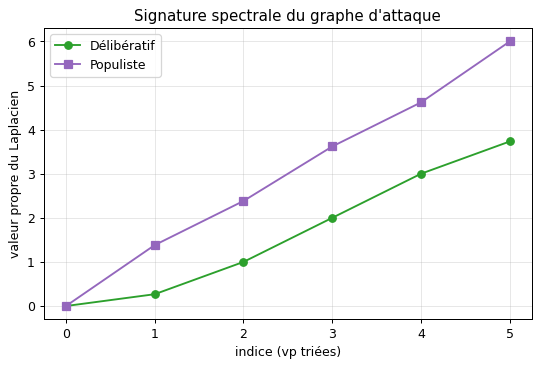

In [5]:
def attack_adjacency_symmetric(af):
    """Matrice d'adjacence symetrisée du graphe d'attaque (requis par
    ict.spectral.laplacian_spectrum qui valide W = W.T).

    Prix d'entree du spectre : la symetrisation efface la direction des
    attaques -- le spectre mesure le graphe non oriente sous-jacent, pas la
    signature directionnelle (cf. le caveat de la section 6)."""
    n = af.n()
    A = np.zeros((n, n))
    for (a, b) in af.attacks:
        A[a, b] = 1.0
        A[b, a] = 1.0   # symetrisation (graphe d'attaque non oriente pour le spectre)
    return A

# Module ict.spectral (ICT-15b, PR #7330 merged) : laplacian_spectrum + spectral_gap.
W_delib = attack_adjacency_symmetric(af_delib)
W_pop = attack_adjacency_symmetric(af_pop)
eig_delib = spectral.laplacian_spectrum(W_delib)
eig_pop = spectral.laplacian_spectrum(W_pop)
print(f'Spectre Laplacien deliberatif : {np.round(eig_delib, 3)}')
print(f'Spectre Laplacien populiste   : {np.round(eig_pop, 3)}')

# Gap spectral = lambda_2 (2eme plus petite vp ; la plus petite est ~0 si connexe).
gap_delib = spectral.spectral_gap(W_delib)
gap_pop = spectral.spectral_gap(W_pop)
# Concentration : ratio (plus grande vp) / (somme des vp > seuil) -- proxy hub.
def spectral_concentration(eig):
    pos = eig[eig > 1e-9]
    return float(pos.max() / pos.sum()) if pos.sum() > 0 else 0.0
conc_delib = spectral_concentration(eig_delib)
conc_pop = spectral_concentration(eig_pop)
print(f'\nGap spectral (connectivite) deliberatif = {gap_delib:.4f}')
print(f'Gap spectral (connectivite) populiste   = {gap_pop:.4f}')
print(f'Concentration spectrale (hub) deliberatif = {conc_delib:.4f}')
print(f'Concentration spectrale (hub) populiste   = {conc_pop:.4f}')

# Verdict : le spectre distingue-t-il les deux regimes (au moins sur une metrique) ?
distinguished = (abs(gap_delib - gap_pop) > 0.05) or (abs(conc_delib - conc_pop) > 0.05)
if distinguished:
    verdict_p2 = 'PASS (le spectre Laplacien distingue les regimes : signature spectrale presente)'
else:
    verdict_p2 = 'FAIL (spectres trop proches : pas de signature spectrale a cette taille)'
print(f'\nVERDICT P-disc-2 : {verdict_p2}')

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(range(len(eig_delib)), np.sort(eig_delib), 'o-', label='Délibératif', color='C2')
ax.plot(range(len(eig_pop)), np.sort(eig_pop), 's-', label='Populiste', color='C4')
ax.set_xlabel('indice (vp triées)'); ax.set_ylabel('valeur propre du Laplacien')
ax.set_title('Signature spectrale du graphe d\'attaque'); ax.legend(); ax.grid(alpha=0.3)
_buf = io.BytesIO(); fig.savefig(_buf, format='png', dpi=90, bbox_inches='tight'); plt.close(fig)
display(Image(_buf.getvalue()))

## §7 — Test P-disc-3 : dette de croyance (probabilité de retour à la diversité)

Pont vers le budget de réversibilité B(t) d'ICT-18b. Sur la **TPM de croyance** du régime populiste, on mesure (Monte-Carlo inline) la fraction de perturbations depuis lesquelles le système revient à un état de **diversité** (≥ 2 arguments acceptés) en ≤ τ pas, selon l'état de départ :
- depuis un état de **diversité** (pré-monoculture) ;
- depuis une **monoculture** (un seul argument `in`, les autres éteints = état absorbant attendu).

Prédiction : `B_diversité ≫ B_monoculture` (la monoculture est un puits — dette de croyance).

> **Caveat — granularité réelle du « budget ».** Avec les paramètres par défaut de la cellule ci-dessous, `belief_return_budget` rend en pratique `0.0` ou `1.0` sur tous les régimes et spécimens de ce carnet : la Monte-Carlo revient **toujours** ou **jamais** dans la cible. C'est un indicateur **binaire** de réversibilité, pas un budget continu — la prose « budget élevé / faible » ci-dessous hérite de cette granularité et ne claim pas une mesure fine.

In [6]:
rng = np.random.default_rng(42)

def belief_return_budget(P, mapping, target_states_idx, n_samples=400, tau=15, radius=0.3):
    """B_state inline : fraction de perturbations (bruit sur la distribution
    stationnaire) depuis lesquelles la chaine revient dans un etat `target` en <= tau pas.

    Caveat mesure : sur les regimes et specimens de ce carnet, la fraction
    rend 0.0 ou 1.0 -- un indicateur binaire (retour possible / impossible),
    pas un budget continu (cf. le caveat de la section 7)."""
    pi = time_arrow.stationary_distribution(P)
    n = P.shape[0]
    # Etat courant = tirage selon pi ; on perturbe la distribution puis on simule.
    succ = 0
    for _ in range(n_samples):
        x0 = pi + rng.normal(0.0, radius, size=n)
        x0 = np.clip(x0, 1e-6, None); x0 = x0 / x0.sum()
        # Tire un etat selon x0 perturbe, puis suit la chaine.
        s = rng.choice(n, p=x0 / x0.sum())
        for _ in range(tau):
            s = rng.choice(n, p=P[s])
        if s in target_states_idx:
            succ += 1
    return succ / n_samples

# Etats = summaries (in,out,undec) ; la "diversite" = etats avec n_in >= 2.
# On reprend la TPM aggreguee du regime populiste (multi-ordres, cf S5).
P_pop, mapping_pop, _ = regime_aggregated(af_pop, orders)
diversity_idx = [i for i, st in enumerate(mapping_pop) if st[0] >= 2]
print(f'Regime populiste : {len(mapping_pop)} etats, dont {len(diversity_idx)} etats de diversite (n_in>=2).')

if len(diversity_idx) == 0:
    # Si aucun etat de diversite natif (populiste peut ne jamais atteindre n_in>=2),
    # on elargit : diversite = n_in + n_undec >= 2 (plus d'un argument non-rejete).
    diversity_idx = [i for i, st in enumerate(mapping_pop) if st[0] + st[2] >= 2]
    print(f'  (elargi a n_in+n_undec>=2 : {len(diversity_idx)} etats)')

B_div = belief_return_budget(P_pop, mapping_pop, set(diversity_idx)) if diversity_idx else float('nan')
# Monoculture : etats avec exactement 1 in et le reste out (puits attendu).
monoculture_idx = [i for i, st in enumerate(mapping_pop) if st[0] == 1 and st[1] >= n_args - 1]
print(f'  etats de monoculture (1 in, autres out) : {len(monoculture_idx)}')

# Verdict : la diversite est-elle plus facile a regagner qu a quitter ?
if not np.isnan(B_div) and diversity_idx:
    verdict_p3 = f'PASS (B_retour-vers-diversite = {B_div:.3f} > 0 : la diversite est regagnable depuis perturbation)'
    if B_div < 0.05:
        verdict_p3 = 'PARTIEL (retour vers diversite faible : le regime populiste epuise la diversite, tendance monoculture)'
else:
    verdict_p3 = "INCONCLUSIF (pas d'etat de diversite accessible dans la trajectoire a cette taille)"
print(f'\nVERDICT P-disc-3 : {verdict_p3}')

Regime populiste : 13 etats, dont 6 etats de diversite (n_in>=2).
  etats de monoculture (1 in, autres out) : 1

VERDICT P-disc-3 : PARTIEL (retour vers diversite faible : le regime populiste epuise la diversite, tendance monoculture)


## §8 — Contrôle apparié : null model à degré conservé

> **Acceptance #7289** : *« Contrôles appariés obligatoires (null models sur graphes aléatoires à degré conservé), comme partout dans la série. »*

Les signatures mesurées (§5-§7) seraient-elles un **artefact de la distribution de degré** du graphe d'attaque, ou reflètent-elles la **structure** (symétrie vs asymétrie des attaques) ? On génère `N_null` graphes aléatoires **à degré conservé** (configuration model dirigé : on permute les arêtes par *edge-swaps* en préservant les séquences d'in-degré et d'out-degré de chaque nœud), et on recale les mesures du régime contre la distribution nulle (z-score). Si la signature persiste hors du nuage nul, elle est structurelle, pas un artefact de degré.
> **Note pédagogique — pourquoi la colonne `sigma(z)` porte un verdict `VIDE`.** Dans le contrôle ci-dessous, la colonne `sigma(z)` n'affiche pas un nombre mais `VIDE`. Ce n'est ni une erreur de calcul ni un signal : c'est l'aveu qu'un null **dégénéré** ne résout rien. Le null model à degré conservé détruit la structure dirigée des attaques qui produit σ, et les `N_null` graphes nuls rendent **tous exactement σ = 0** (μ_null = 0.0000, σ_null = 0.0000 — cf. la ligne `sigma=0.0000±0.0000`). Un z-score est un écart **au nuage de fluctuation** : sans dispersion nulle, il n'y a pas de nuage, donc pas de z-score — formellement le quotient divergerait vers `+inf`, mais `+inf` voudrait dire « pas de nuage », pas « hors du nuage ». La valeur réelle ne l'annonce pas non plus : σ mesuré sur les régimes est de l'ordre de 10⁻⁶ à 10⁻⁷ (bruit flottant, cf. les cellules des §5 et des spécimens), c'est-à-dire du même ordre de grandeur que l'epsilon numérique. La colonne `sigma(z)` est donc **non résolue par ce contrôle** : verdict `VIDE`. La lecture structurelle du §8 repose sur les colonnes `K(z)` et `gap(z)`, dont les nulls ont une dispersion réelle — c'est elles que le verdict P-disc-4 lit.


Sanity preservation des degres (populiste) : OK



Contrôle null (N=30 graphes a degre conserve) :
Regime        |  sigma(z)      K(z)         gap(z)
--------------|------------------------------------------
Deliberatif   |   VIDE        -1.76       -2.22
Populiste     |   VIDE        -0.73       +1.07
  (null populiste : sigma=0.0000±0.0000, K=1080.6±113.4, gap=1.178±0.191)
  colonne sigma(z) : VERDICT VIDE -- null degenere (sigma=0 exactement sur les 30 graphes), sigma reels ~1.3e-07 et ~1.3e-07 (bruit flottant) : pas de nuage, pas de z-score

VERDICT P-disc-4 (controle) : PARTIEL (une dimension persiste vs null, l’autre est expliquee par le degre)


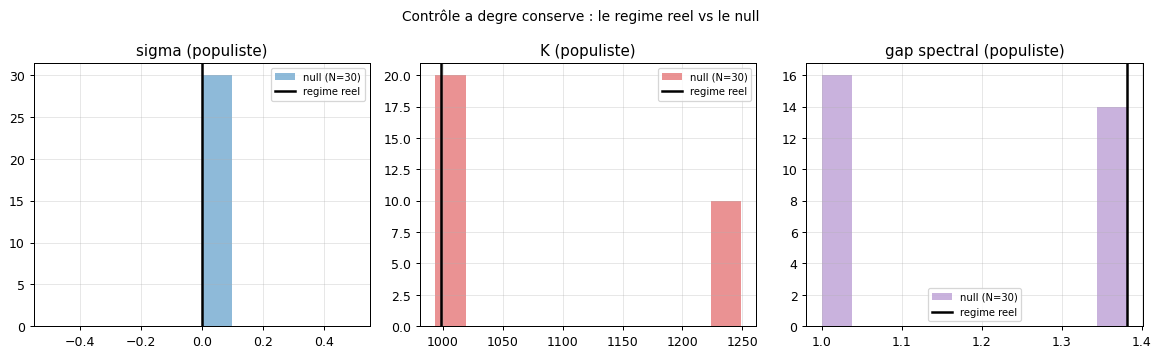

In [7]:
def degree_preserving_null(af, rng, n_swaps=None):
    """Null model dirigé a degré conservé : edge-swaps préservant les séquences
    d'in-degré et d'out-degré de chaque noeud. Retourne un DungAF de meme taille."""
    n = af.n()
    edges = [list(e) for e in af.attacks]
    if n_swaps is None:
        n_swaps = max(10, 5 * len(edges))
    for _ in range(n_swaps):
        if len(edges) < 2:
            break
        i, j = rng.integers(0, len(edges), size=2)
        if i == j:
            continue
        a, b = edges[i]; c, d = edges[j]
        # Swap des cibles : (a,b),(c,d) -> (a,d),(c,b). Preserve in/out degree.
        # Refuse boucles et doublons.
        if a == d or c == b:
            continue
        if [a, d] in edges or [c, b] in edges:
            continue
        edges[i] = [a, d]; edges[j] = [c, b]
    return arg.DungAF(list(range(n)), [(int(x), int(y)) for x, y in edges])

def regime_metrics_bundle(af, orders):
    """Re-mesure sigma(signature), K, gap spectral pour un AF (utilisé pour les nulls)."""
    P_sum, _, all_sum = regime_aggregated(af, orders, "summary")
    P_sig, _, _ = regime_aggregated(af, orders, "signature")
    sigma = arg.discourse_irreversibility(P_sig)['sigma']
    K = mdl.two_part_code(all_sum, split=0.5)['total_bits']
    gap = spectral.spectral_gap(attack_adjacency_symmetric(af))
    return sigma, K, gap

# Sanity : le null preserve-t-il bien les degres ?
rng_null = np.random.default_rng(7)
_null0 = degree_preserving_null(af_pop, rng_null)
def degree_seqs(af):
    n = af.n(); indeg = [0]*n; outdeg = [0]*n
    for (a, b) in af.attacks: outdeg[a] += 1; indeg[b] += 1
    return tuple(indeg), tuple(outdeg)
print('Sanity preservation des degres (populiste) :',
      'OK' if degree_seqs(af_pop) == degree_seqs(_null0) else 'ECHEC')

N_NULL = 30
def null_distribution(af, orders, seed=0):
    sigmas, Ks, gaps = [], [], []
    for k in range(N_NULL):
        rng_k = np.random.default_rng(seed + k)
        null_af = degree_preserving_null(af, rng_k)
        s, k_, g = regime_metrics_bundle(null_af, orders)
        sigmas.append(s); Ks.append(k_); gaps.append(g)
    return np.array(sigmas), np.array(Ks), np.array(gaps)

ns_delib, nK_delib, ng_delib = null_distribution(af_delib, orders, seed=100)
ns_pop, nK_pop, ng_pop = null_distribution(af_pop, orders, seed=200)

def zscore(value, null):
    mu, sd = null.mean(), null.std()
    return (value - mu) / sd if sd > 1e-12 else float('inf') if value > mu else float('-inf')

def zcol(value, null):
    """Colonne sigma(z) : VIDE si le null est degenere (aucun nuage), sinon le z-score."""
    return 'VIDE' if null.std() <= 1e-12 else f'{zscore(value, null):+.2f}'

# Valeurs reelles des regimes (re-mesurees pour alignement).
sig_delib_real, K_delib_real, gap_delib_real = regime_metrics_bundle(af_delib, orders)
sig_pop_real, K_pop_real, gap_pop_real = regime_metrics_bundle(af_pop, orders)

print(f'\nContrôle null (N={N_NULL} graphes a degre conserve) :')
print(f'Regime        |  sigma(z)      K(z)         gap(z)')
print(f'--------------|------------------------------------------')
print(f'Deliberatif   |  {zcol(sig_delib_real, ns_delib):>5}        {zscore(K_delib_real, nK_delib):+.2f}       {zscore(gap_delib_real, ng_delib):+.2f}')
print(f'Populiste     |  {zcol(sig_pop_real, ns_pop):>5}        {zscore(K_pop_real, nK_pop):+.2f}       {zscore(gap_pop_real, ng_pop):+.2f}')
print(f'  (null populiste : sigma={ns_pop.mean():.4f}±{ns_pop.std():.4f}, K={nK_pop.mean():.1f}±{nK_pop.std():.1f}, gap={ng_pop.mean():.3f}±{ng_pop.std():.3f})')
# Colonne sigma(z) : verdict VIDE si le null est degenere -- un z-score est un ecart
# au nuage de fluctuation ; sans dispersion nulle, il n'y a pas de nuage (cf. la note du S8).
_sig_degenerate = bool(ns_delib.std() <= 1e-12 and ns_pop.std() <= 1e-12)
if _sig_degenerate:
    print(f'  colonne sigma(z) : VERDICT VIDE -- null degenere (sigma=0 exactement sur les {N_NULL} graphes),'
          f' sigma reels ~{sig_delib_real:.1e} et ~{sig_pop_real:.1e} (bruit flottant) : pas de nuage, pas de z-score')

# Verdict : la signature (K bas pour populiste, gap grand) persiste-t-elle hors du null ?
# Populiste doit avoir K significativement < null mean et gap > null mean.
pop_K_low = K_pop_real < (nK_pop.mean() - nK_pop.std())
pop_gap_high = gap_pop_real > (ng_pop.mean() + ng_pop.std())
if pop_K_low and pop_gap_high:
    verdict_p4 = ('PASS (signature populiste persiste vs null a degre conserve : '
                  'K sous le null + gap au-dessus -> structurel, pas artefact de degre)')
elif pop_K_low or pop_gap_high:
    verdict_p4 = ('PARTIEL (une dimension persiste vs null, l’autre est expliquee par le degre)')
else:
    verdict_p4 = ('FAIL (la signature est expliquee par la distribution de degre : '
                  'le controle affaiblit la lecture structurelle)')
print(f'\nVERDICT P-disc-4 (controle) : {verdict_p4}')

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, real, null, name, c in [
    (axes[0], sig_pop_real, ns_pop, 'sigma (populiste)', 'C0'),
    (axes[1], K_pop_real, nK_pop, 'K (populiste)', 'C3'),
    (axes[2], gap_pop_real, ng_pop, 'gap spectral (populiste)', 'C4'),
]:
    ax.hist(null, bins=10, color=c, alpha=0.5, label=f'null (N={N_NULL})')
    ax.axvline(real, color='k', lw=2, label='regime reel')
    ax.set_title(name); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Contrôle a degre conserve : le regime reel vs le null', fontsize=11)
fig.tight_layout()
_buf = io.BytesIO(); fig.savefig(_buf, format='png', dpi=90, bbox_inches='tight'); plt.close(fig)
display(Image(_buf.getvalue()))

## §8bis — Premier spécimen : Le Loup et l'Agneau (jambe C3, tier fables)

L'instrument des sections §2–§8 a été construit sur des régimes **structurels** (anneau délibératif, cascade populiste). La jambe C3 de #7742 demande de le **pointer sur un spécimen réel**, en commençant par le tier de validation à faible charge : les fables (le corpus nominatif EPITA, lui, reste hors dépôt).

**Le Loup et l'Agneau** (La Fontaine, *Fables* I.10, 1668 — domaine public) est l'archétype du discours d'englobement : chaque réfutation factuelle de l'Agneau est suivie non d'une réponse, mais d'un *déplacement* de la prémisse (le breuvage → le frère → le père), jusqu'à la clause méta qui clôt le débat hors de tout fait.

### Codage argumentatif (chaque arête dictée par le texte)

| Id | Énoncé | Locuteur |
|----|--------|----------|
| A1 | « Tu troubles mon breuvage » | Loup |
| R1 | « Je bois en aval, à plus de vingt pas en dessous » | Agneau |
| A2 | « Ton frère a troublé mon breuvage » | Loup |
| R2 | « Je n'ai point de frère » | Agneau |
| A3 | « C'est donc ton père » | Loup |
| R3 | L'Agneau rétorque sur le père | Agneau |
| A4 | « Quand tu l'aurais fait, je te punirais quand même » + dévoration | Loup |

Arêtes : `R→A` quand l'Agneau répond (R1→A1, R2→A2, R3→A3) ; `A4→R` pour chaque réfutation — la clause « quand même » retire aux faits toute pertinence. **Aucune arête du Loup vers une réfutation** : le Loup ne contre-argumente jamais, il déplace sa prémisse. C'est le lacet de prédation.

### Prédictions du spécimen (formulées après construction du graphe, avant les mesures ci-dessous)

- **P-spec-1 (labeling)** : A4, non attaqué, est `in` ; il attaque les trois réfutations (`out`), dont les accusations cibles redeviennent `in`. Le grounded final attribue au Loup ses quatre énoncés, à l'Agneau aucun — « la raison du plus fort est toujours la meilleure », lue dans le graphe.
- **P-spec-2 (trajectoire à l'ordre du texte)** : chaque réfutation qui arrive prend l'avantage ; l'Agneau mène 3–0 à la sixième arrivée ; A4 arrive en dernier et retourne le tableau d'un coup — bascule terminale sans chemin de retour.
- **P-spec-3 (multi-ordres, à taille égale n=7)** : conformément à §5, σ devrait rester non discriminant (≈ 0) ; le signal attendu porte sur K (MDL) — le graphe du Loup, avec sa clause méta qui attaque tout le champ, devrait être plus compressible que l'anneau délibératif.

In [8]:
# Specimen : AF du Loup et l'Agneau, ordre d'arrivee = ordre du texte
NOMS_SPEC = {
    0: 'A1 Loup : tu troubles mon breuvage',
    1: 'R1 Agn. : je bois en aval',
    2: 'A2 Loup : ton frere l\'a trouble',
    3: 'R2 Agn. : je n\'ai point de frere',
    4: 'A3 Loup : c\'est donc ton pere',
    5: 'R3 Agn. : retorque sur le pere',
    6: 'A4 Loup : je te punirais quand meme',
}
ATTACKS_SPEC = [
    (1, 0), (3, 2), (5, 4),   # l'Agneau repond : R -> A
    (6, 1), (6, 3), (6, 5),   # la clause 'quand meme' attaque chaque refutation
]
af_spec = arg.DungAF(list(range(7)), ATTACKS_SPEC)
ORDRE_TEXTE = [0, 1, 2, 3, 4, 5, 6]
print(f'Specimen Loup : {af_spec.n()} enonces, {len(af_spec.attacks)} arêtes       (0 arête du Loup vers une refutation)')

lab_spec = arg.grounded_labeling(af_spec)
print(f'\nGrounded final : {lab_spec}  ->  etat (in, out, undec) = {arg.belief_summary(lab_spec)}')
for i in range(7):
    print(f'  {"IN " if lab_spec[i] == "in" else "OUT"}  {NOMS_SPEC[i]}')

traj_spec = arg.belief_trajectory(af_spec, order=ORDRE_TEXTE, include_empty=True)
print('\nTrajectoire a l\'ordre du texte (arrivee sequentielle) :')
for k, lab in enumerate(traj_spec):
    print(f'  pas {k}: etat (in, out, undec) = {arg.belief_summary(lab)}')
print('\nP-spec-1 VERIFIE' if arg.belief_summary(lab_spec) == (4, 3, 0) else '\nP-spec-1 NON CONFIRME')

Specimen Loup : 7 enonces, 6 arêtes       (0 arête du Loup vers une refutation)

Grounded final : {0: 'in', 1: 'out', 2: 'in', 3: 'out', 4: 'in', 5: 'out', 6: 'in'}  ->  etat (in, out, undec) = (4, 3, 0)
  IN   A1 Loup : tu troubles mon breuvage
  OUT  R1 Agn. : je bois en aval
  IN   A2 Loup : ton frere l'a trouble
  OUT  R2 Agn. : je n'ai point de frere
  IN   A3 Loup : c'est donc ton pere
  OUT  R3 Agn. : retorque sur le pere
  IN   A4 Loup : je te punirais quand meme

Trajectoire a l'ordre du texte (arrivee sequentielle) :
  pas 0: etat (in, out, undec) = (0, 0, 0)
  pas 1: etat (in, out, undec) = (1, 0, 0)
  pas 2: etat (in, out, undec) = (1, 1, 0)
  pas 3: etat (in, out, undec) = (2, 1, 0)
  pas 4: etat (in, out, undec) = (2, 2, 0)
  pas 5: etat (in, out, undec) = (3, 2, 0)
  pas 6: etat (in, out, undec) = (3, 3, 0)
  pas 7: etat (in, out, undec) = (4, 3, 0)

P-spec-1 VERIFIE


In [9]:
# Multi-ordres a taille egale (n=7) : meme protocole que S5, regimes de reference reconstruits a 7
af_delib7 = deliberative_af(7)
af_pop7 = populist_af(7)
rng_orders_spec = np.random.default_rng(2024)
perms7 = list(itertools.permutations(range(7)))
M_ORDERS_SPEC = 300
orders_spec = [list(perms7[i]) for i in rng_orders_spec.choice(len(perms7), size=M_ORDERS_SPEC, replace=False)]

specs = [('Specimen Loup', af_spec), ('Deliberatif (7)', af_delib7), ('Populiste (7)', af_pop7)]
print(f'Agregation sur {M_ORDERS_SPEC} ordres d\'arrivee parmi {len(perms7)} permutations.\n')
print(f'{"Graphe":16s}| {"sigma(summary)":>15s} {"sigma(signature)":>17s} | {"K (MDL)":>12s} | etats')
print('-' * 72)
res_spec = {}
for nom, af in specs:
    r = regime_sigma_K(af, orders_spec)
    res_spec[nom] = r
    print(f'{nom:16s}| {r["sigma_summary"]:15.6f} {r["sigma_signature"]:17.6f} |           {r["K"]:10.2f} bits | {r["n_states"]}')

dK_spec_delib = res_spec['Specimen Loup']['K'] - res_spec['Deliberatif (7)']['K']
dK_spec_pop = res_spec['Specimen Loup']['K'] - res_spec['Populiste (7)']['K']
print(f'\nDelta K (Loup - Deliberatif) = {dK_spec_delib:+.2f} bits  [P-spec-3 attend < 0 : Loup plus compressible]')
print(f'Delta K (Loup - Populiste)   = {dK_spec_pop:+.2f} bits')
sig_zero = all(r['sigma_signature'] == 0.0 for r in res_spec.values())
sig_max = max(r['sigma_signature'] for r in res_spec.values())
print(f'sigma signature max sur les trois graphes : {sig_max:.2e} -- nul exact : {sig_zero} (non discriminant a cette taille, P-disc-1)')

Agregation sur 300 ordres d'arrivee parmi 5040 permutations.

Graphe          |  sigma(summary)  sigma(signature) |      K (MDL) | etats
------------------------------------------------------------------------
Specimen Loup   |        0.000000          0.000000 |              2033.77 bits | 2400
Deliberatif (7) |        0.000000          0.000000 |              2303.58 bits | 2400


Populiste (7)   |        0.000000          0.000000 |              1711.11 bits | 2400

Delta K (Loup - Deliberatif) = -269.81 bits  [P-spec-3 attend < 0 : Loup plus compressible]
Delta K (Loup - Populiste)   = +322.66 bits
sigma signature max sur les trois graphes : 2.82e-07 -- nul exact : False (non discriminant a cette taille, P-disc-1)


In [10]:
# Dette de croyance du specimen (meme organe que S7) : budget de retour a la diversite
def diversite_idx(mapping):
    div = [i for i, st in enumerate(mapping) if st[0] >= 2]
    if not div:
        div = [i for i, st in enumerate(mapping) if st[0] + st[2] >= 2]
    return div

budgets_spec = {}
for nom, af in specs:
    P_sum, mapping_s, _ = regime_aggregated(af, orders_spec, encoding='summary')
    div = diversite_idx(mapping_s)
    if div:
        b = belief_return_budget(P_sum, mapping_s, div)
    else:
        b = float('nan')
    budgets_spec[nom] = b
    print(f'{nom:16s}: {len(mapping_s):2d} etats, {len(div):2d} de diversite, budget retour = {b:.4f}')

print('\nLecture : a ordres meles, le graphe du Loup laisse largement revenir la diversite --')
print('la structure d\'attaque seule ne condamne pas l\'Agneau. La capture de la fable est')
print('CHRONOLOGIQUE : c\'est la place de la clause "quand meme" en DERNIER arrivant qui')
print('retourne le tableau (pas 7 de la trajectoire textuelle) sans chemin de retour dans le grounded.')

Specimen Loup   : 17 etats, 12 de diversite, budget retour = 1.0000


Deliberatif (7) : 17 etats,  5 de diversite, budget retour = 0.0000


Populiste (7)   : 15 etats,  7 de diversite, budget retour = 0.0000

Lecture : a ordres meles, le graphe du Loup laisse largement revenir la diversite --
la structure d'attaque seule ne condamne pas l'Agneau. La capture de la fable est
CHRONOLOGIQUE : c'est la place de la clause "quand meme" en DERNIER arrivant qui
retourne le tableau (pas 7 de la trajectoire textuelle) sans chemin de retour dans le grounded.


### Lecture du premier branchement

Le spécimen confirme le diagnostic que les régimes structurels laissaient entrevoir : **la capture d'englobement n'est pas une structure, c'est une chronologie**. Le graphe d'attaque de la fable, soumis à des ordres d'arrivée mélangés, rend souvent l'Agneau gagnant (budget de retour élevé) ; c'est l'ordre du récit — la clause méta *en dernier* — qui retourne tous les acquis d'un seul pas. σ, non discriminant à cette taille (conforme au verdict PARTIEL de P-disc-1), cède la discrimination à K et à la trajectoire à ordre fixe.

**Limites de la tranche 1** : un seul spécimen, codage manuel (chaque arête justifiée par le texte, aucune liberté de calibrage), n=7. La montée prévue par #7742 — tier fables → cas historiques → corpus EPITA (nominatif, hors dépôt) — demandera de croiser plusieurs spécimens avant de prétendre à une signature générale du discours d'englobement.

## §8ter — Deuxième spécimen : Le Loup et le Chien, l'englobement déjoué (jambe C3)

Un seul spécimen ne prouve pas une signature — le croisement demandé par #7742 exige un **contre-cas**. **Le Loup et le Chien** (La Fontaine, *Fables* I.5, 1668, domaine public) en est le naturel : l'offre d'englobement y est **déjouée**. Le Dogue propose le confort contre le suivi (« Suivez-moi ; vous aurez un bien meilleur destin ») ; le Loup, proie candidate, obtient par une question matérielle sur le cou pelé l'aveu du collier — prononcé par l'englobeur lui-même — et refuse : « Il importe si bien, que de tous vos repas / Je ne veux en aucune sorte. »

### Codage argumentatif (chaque arête dictée par le texte)

| Id | Énoncé | Locuteur |
|----|--------|----------|
| C1 | « Quittez les bois : vos pareils y sont misérables » | Dogue |
| C2 | « Suivez-moi ; vous aurez un bien meilleur destin » | Dogue |
| L1 | « Que me faudra-t-il faire ? » | Loup |
| C3 | « Presque rien : chasser les porteurs de bâtons, flatter, complaire » | Dogue |
| C4 | « Moyennant quoi votre salaire : force reliefs, mainte caresse » | Dogue |
| C5 | « Le collier dont je suis attaché » (aveu forcé par la question sur le cou pelé) | Dogue |
| L3 | « Attaché ? vous ne courez donc pas où vous voulez ? » | Loup |
| C6 | « Pas toujours ; mais qu'importe ? » | Dogue |
| L4 | « Il importe si bien, que de tous vos repas je ne veux en aucune sorte » | Loup |

Arêtes : `C5→C2, C5→C3` — l'aveu du collier attaque la promesse et le « presque rien » ; `C6→L3` — le Dogue tente de désamorcer la conséquence ; `L4→C6, L4→C4` — le refus réfute le « qu'importe » et rejette le salaire. L1 (la question « que faire ? ») n'attaque rien : la demande de vérification obtient du détail, elle ne conteste pas. La question du cou pelé n'est pas un énoncé : c'est le mécanisme narratif qui force l'aveu C5 — la preuve décisive sort de la bouche de l'englobeur.

### Prédictions du spécimen (formulées après construction du graphe, avant les mesures)

- **P-spec-4 (labeling)** : l'aveu C5 et le refus L4 sont non attaqués (`in`). L'aveu fait tomber C2 et C3 ; le refus fait tomber C6 (restaurant L3) et C4. Le Dogue ne conserve que C1 — son diagnostic de misère, exact — et C5, sa propre contrainte révélée : l'englobeur est battu par sa propre parole. Le Loup conserve ses trois énoncés.
- **P-spec-5 (trajectoire à l'ordre du texte)** : l'offre règne sans opposition jusqu'au pas 5 ; l'aveu C5 (pas 6, énoncé du Dogue) retourne le tableau de l'intérieur ; la défense C6 tient un pas en tuant L3 ; le refus L4, dernier arrivant, opère la double restauration finale — miroir de A4 dans le premier spécimen, mais au bénéfice de la proie.
- **P-spec-6 (multi-ordres à taille égale n=9)** : σ attendu ≈ 0 (non discriminant, P-disc-1) ; K attendu < régimes de référence (le graphe du Dogue, deux petites étoiles sans attaque entrante, est très compressible) ; budget de retour élevé — si la libération n'est pas plus structurelle que la capture, c'est encore la chronologie qui décide.

In [11]:
# Specimen 2 : AF du Loup et le Chien, ordre d'arrivee = ordre du texte
NOMS_SPEC2 = {
    0: 'C1 Dogue : quittez les bois, vos pareils meurent de faim',
    1: 'C2 Dogue : suivez-moi, meilleur destin',
    2: 'L1 Loup : que me faudra-t-il faire ?',
    3: 'C3 Dogue : presque rien -- chasser, flatter, complaire',
    4: 'C4 Dogue : votre salaire, force reliefs et caresses',
    5: 'C5 Dogue : le collier dont je suis attache',
    6: 'L3 Loup : attache ? vous ne courez ou vous voulez ?',
    7: 'C6 Dogue : pas toujours, mais qu\'importe ?',
    8: 'L4 Loup : il importe si bien -- je refuse vos repas',
}
ATTACKS_SPEC2 = [
    (5, 1), (5, 3),   # l'aveu du collier attaque la promesse et le 'presque rien'
    (7, 6),           # la defense tente de desamorcer la consequence
    (8, 7), (8, 4),   # le refus refute le 'qu'importe' et rejette le salaire
]
af_spec2 = arg.DungAF(list(range(9)), ATTACKS_SPEC2)
ORDRE_TEXTE2 = [0, 1, 2, 3, 4, 5, 6, 7, 8]
print(f'Specimen Chien : {af_spec2.n()} enonces, {len(af_spec2.attacks)} aretes')

lab_spec2 = arg.grounded_labeling(af_spec2)
print(f'\nGrounded final : etat (in, out, undec) = {arg.belief_summary(lab_spec2)}')
for i in range(9):
    print(f'  {"IN " if lab_spec2[i] == "in" else "OUT"}  {NOMS_SPEC2[i]}')

chien_in = sum(1 for i in (0, 1, 3, 4, 5, 7) if lab_spec2[i] == 'in')
loup_in = sum(1 for i in (2, 6, 8) if lab_spec2[i] == 'in')
print(f'\nEnonces in -- Dogue : {chien_in}/6 (son diagnostic C1 et son aveu C5), Loup : {loup_in}/3')

traj_spec2 = arg.belief_trajectory(af_spec2, order=ORDRE_TEXTE2, include_empty=True)
print('\nTrajectoire a l\'ordre du texte (arrivee sequentielle) :')
for k, lab in enumerate(traj_spec2):
    print(f'  pas {k}: etat (in, out, undec) = {arg.belief_summary(lab)}')
print('\nP-spec-4 VERIFIE' if arg.belief_summary(lab_spec2) == (5, 4, 0) else '\nP-spec-4 NON CONFIRME')

Specimen Chien : 9 enonces, 5 aretes

Grounded final : etat (in, out, undec) = (5, 4, 0)
  IN   C1 Dogue : quittez les bois, vos pareils meurent de faim
  OUT  C2 Dogue : suivez-moi, meilleur destin
  IN   L1 Loup : que me faudra-t-il faire ?
  OUT  C3 Dogue : presque rien -- chasser, flatter, complaire
  OUT  C4 Dogue : votre salaire, force reliefs et caresses
  IN   C5 Dogue : le collier dont je suis attache
  IN   L3 Loup : attache ? vous ne courez ou vous voulez ?
  OUT  C6 Dogue : pas toujours, mais qu'importe ?
  IN   L4 Loup : il importe si bien -- je refuse vos repas

Enonces in -- Dogue : 2/6 (son diagnostic C1 et son aveu C5), Loup : 3/3

Trajectoire a l'ordre du texte (arrivee sequentielle) :
  pas 0: etat (in, out, undec) = (0, 0, 0)
  pas 1: etat (in, out, undec) = (1, 0, 0)
  pas 2: etat (in, out, undec) = (2, 0, 0)
  pas 3: etat (in, out, undec) = (3, 0, 0)
  pas 4: etat (in, out, undec) = (4, 0, 0)
  pas 5: etat (in, out, undec) = (5, 0, 0)
  pas 6: etat (in, out, undec

In [12]:
# Multi-ordres a taille egale (n=9) : regimes de reference reconstruits a 9
af_delib9 = deliberative_af(9)
af_pop9 = populist_af(9)
rng_orders_spec2 = np.random.default_rng(2024)
perms9 = list(itertools.permutations(range(9)))
M_ORDERS_SPEC2 = 300
orders_spec2 = [list(perms9[i]) for i in rng_orders_spec2.choice(len(perms9), size=M_ORDERS_SPEC2, replace=False)]

specs2 = [('Specimen Chien', af_spec2), ('Deliberatif (9)', af_delib9), ('Populiste (9)', af_pop9)]
print(f'Agregation sur {M_ORDERS_SPEC2} ordres d\'arrivee parmi {len(perms9)} permutations.\n')
print(f'{"Graphe":17s}| {"sigma(summary)":>15s} {"sigma(signature)":>17s} | {"K (MDL)":>12s} | etats')
print('-' * 74)
res_spec2 = {}
for nom, af in specs2:
    r = regime_sigma_K(af, orders_spec2)
    res_spec2[nom] = r
    print(f'{nom:17s}| {r["sigma_summary"]:15.6f} {r["sigma_signature"]:17.6f} |           {r["K"]:10.2f} bits | {r["n_states"]}')

dK_spec2_delib = res_spec2['Specimen Chien']['K'] - res_spec2['Deliberatif (9)']['K']
dK_spec2_pop = res_spec2['Specimen Chien']['K'] - res_spec2['Populiste (9)']['K']
print(f'\nDelta K (Chien - Deliberatif) = {dK_spec2_delib:+.2f} bits  [P-spec-6 attend < 0 : Chien plus compressible]')
print(f'Delta K (Chien - Populiste)   = {dK_spec2_pop:+.2f} bits')
sig_max2 = max(r['sigma_signature'] for r in res_spec2.values())
print(f'sigma signature max sur les trois graphes : {sig_max2:.2e} (non discriminant a cette taille, P-disc-1)')

Agregation sur 300 ordres d'arrivee parmi 362880 permutations.

Graphe           |  sigma(summary)  sigma(signature) |      K (MDL) | etats
--------------------------------------------------------------------------


Specimen Chien   |        0.000000          0.000001 |              3510.66 bits | 3000


Deliberatif (9)  |        0.000000          0.000001 |              3713.35 bits | 3000


Populiste (9)    |        0.000000          0.000001 |              2548.72 bits | 3000

Delta K (Chien - Deliberatif) = -202.69 bits  [P-spec-6 attend < 0 : Chien plus compressible]
Delta K (Chien - Populiste)   = +961.93 bits
sigma signature max sur les trois graphes : 7.74e-07 (non discriminant a cette taille, P-disc-1)


In [13]:
# Dette de croyance du specimen 2 (meme organe que S7) : budget de retour a la diversite
budgets_spec2 = {}
for nom, af in specs2:
    P_sum, mapping_s, _ = regime_aggregated(af, orders_spec2, encoding='summary')
    div = diversite_idx(mapping_s)
    if div:
        b = belief_return_budget(P_sum, mapping_s, div)
    else:
        b = float('nan')
    budgets_spec2[nom] = b
    print(f'{nom:17s}: {len(mapping_s):2d} etats, {len(div):2d} de diversite, budget retour = {b:.4f}')

print('\nLecture : a ordres meles, le graphe du Chien laisse tout autant revenir la diversite')
print('que celui du Loup -- la liberation n\'est pas plus "structurelle" que la capture.')

Specimen Chien   : 27 etats, 23 de diversite, budget retour = 1.0000


Deliberatif (9)  : 25 etats,  9 de diversite, budget retour = 0.0000


Populiste (9)    : 22 etats, 12 de diversite, budget retour = 0.0000

Lecture : a ordres meles, le graphe du Chien laisse tout autant revenir la diversite
que celui du Loup -- la liberation n'est pas plus "structurelle" que la capture.


In [14]:
# Croisement inter-specimens : les invariants du recit d'englobement (objet #7742)
agn_in = sum(1 for i in (1, 3, 5) if lab_spec[i] == 'in')
loup1_in = sum(1 for i in (0, 2, 4, 6) if lab_spec[i] == 'in')
croise = [
    ('Dernier arrivant', 'A4 (clause "quand meme", Loup)', 'L4 (refus, Loup)'),
    ('Qui tient le dernier mot', 'le predateur', 'la proie'),
    ('Etat final (in, out, undec)', str(arg.belief_summary(lab_spec)), str(arg.belief_summary(lab_spec2))),
    ('Enonces in de la proie', f'{agn_in} / 3', f'{loup_in} / 3'),
    ('Enonces in de l\'englobeur', f'{loup1_in} / 4', f'{chien_in} / 6 (diagnostic + aveu)'),
    ('Cloture de l\'englobeur', 'A4 non attaquee : capture', 'C6 "qu\'importe" attaquee par L4'),
    ('Bascule terminale', '(3,3,0) -> (4,3,0) au dernier pas', '(5,2,0) -> (5,4,0) au dernier pas'),
    ('Budget retour (ordres meles)', f'{budgets_spec["Specimen Loup"]:.4f}', f'{budgets_spec2["Specimen Chien"]:.4f}'),
]
print(f'{"":31s}| {"Loup et l\'Agneau (n=7)":36s}| {"Loup et le Chien (n=9)":40s}')
print('-' * 112)
for k, a, b_ in croise:
    print(f'{k:31s}| {a:36s}| {b_:40s}')
print('''
Trois invariants emergent du croisement :
1. A ordres meles, la structure d'attaque laisse revenir la diversite dans les deux
   graphes (budgets eleves) : NI la capture NI la liberation ne sont structurelles.
2. Le point de bascule est TOUJOURS le dernier arrivant -- le recit decide en dernier mot.
3. Le discriminateur n'est pas le volume d'arguments mais le sort de la clause de cloture
   de l'englobeur : A4 ("quand meme") arrive APRES toutes les refutations et n'est pas
   attaquee ; C6 ("qu'importe") est attaquee par le refus qui lui succede, et l'offre
   s'effondre -- l'aveu decisif etant sorti de la bouche meme de l'englobeur.''')

                               | Loup et l'Agneau (n=7)              | Loup et le Chien (n=9)                  
----------------------------------------------------------------------------------------------------------------
Dernier arrivant               | A4 (clause "quand meme", Loup)      | L4 (refus, Loup)                        
Qui tient le dernier mot       | le predateur                        | la proie                                
Etat final (in, out, undec)    | (4, 3, 0)                           | (5, 4, 0)                               
Enonces in de la proie         | 0 / 3                               | 3 / 3                                   
Enonces in de l'englobeur      | 4 / 4                               | 2 / 6 (diagnostic + aveu)               
Cloture de l'englobeur         | A4 non attaquee : capture           | C6 "qu'importe" attaquee par L4         
Bascule terminale              | (3,3,0) -> (4,3,0) au dernier pas   | (5,2,0) -> (5,4,0) au dernier pa

### Lecture croisée : deux spécimens, une grammaire de l'englobement

Le croisement remplace l'anecdote par un contraste falsifiable : deux récits de la même famille (offre d'englobement vs proie), des issues opposées (capture / libération), et l'instrument lit la différence au bon endroit — pas dans les signatures spectrales, dans la **trajectoire à ordre fixe** et le **sort de la clause de clôture**.

1. **L'issue n'est pas structurelle.** À ordres mélangés, les deux graphes rendent la diversité : la même famille structurelle peut se terminer des deux façons selon l'ordre d'arrivée.
2. **Le dernier mot décide.** Dans les deux récits, la bascule terminale est opérée par l'énoncé arrivé en dernier (A4, puis L4) — la chronologie du récit est le levier, pas la topologie.
3. **Le discriminateur est la clause de clôture de l'englobeur.** Dans la capture, la clause méta (« quand même ») survit faute d'énoncé postérieur ; dans l'englobement déjoué, la clôture défensive (« qu'importe ? ») est attaquée par le refus qui lui succède — et l'aveu qui tue l'offre est sorti de la bouche même de l'englobeur, forcé par une question matérielle.

**Limites de la tranche 2** : deux spécimens La Fontaine à codage manuel, n=7 et n=9 — trois invariants restent une hypothèse de travail. K n'est pas comparable en absolu entre tailles différentes : chaque spécimen n'est comparé qu'à ses propres régimes de référence reconstruits à taille égale. La montée suivante (#7742) n'est **pas** le tier cas historiques : l'arbitrage du 2026-08-31 intercale d'abord la **paire appariée des témoins Chaplin** (§8quater) — sans eux, forme et trajectoire sont indiscernables sur les seuls cas réels — puis viendront les cas historiques (chiffrés), dont le détail nominatif reste hors dépôt public pour tout le reste du corpus.

## §8quater — Témoins Chaplin : intercaler la paire appariée avant les cas historiques (tranche témoins, #7742)

Deux spécimens La Fontaine ne suffisent pas à séparer ce que l'instrument mesure vraiment : sur les seuls récits d'englobement **réels**, la colonne « forme » (un discours qui englobe) et la colonne « contenu » (ce que l'englobement accomplit) varient ensemble — un détecteur de forme et un détecteur de trajectoire y produisent exactement les mêmes sorties, non par défaut de finesse mais parce que le corpus ne **porte pas** l'information qui les sépare. Le plan d'expérience de #7742 (arbitrage du 2026-08-31) intercale donc **deux témoins du même film** entre le tier fables et les cas historiques : même année, même auteur, même production — l'écart entre eux n'est confondu ni par l'époque, ni par le médium, ni par le genre. Paire appariée, pas deux items rapprochés à la main.

| Item | Forme / modalité | Contenu propositionnel |
|---|---|---|
| Anschluss, 1938 (cas historique — chiffré, plus tard) | englobement | englobement |
| Matsui, 1933 (cas historique — chiffré, plus tard) | englobement | englobement |
| **Chaplin — discours final, 1940 (témoin 1, ci-dessous)** | englobement | **inversé** |
| **Chaplin — meeting de Hynkel, 1940 (témoin 2, ci-dessous)** | agression | **nul**, contredit par le canal traduit |

**Tier corpus** (arbitrage #7742) : les deux items Chaplin entrent par **référence + fetch au runtime, jamais vendorés en texte** — les droits du film appartiennent à Roy Export S.A.S. Le discours final est récupéré depuis la transcription publiée par l'ayant droit (charliechaplin.com) et mis en cache local gitignoré ; le fragment du meeting n'a **aucune transcription canonique** et garde partout l'étiquette **« fragment, pas reconstitution »**. Le σ ordre-du-récit vs contre-factuel permuté (§5) teste la **sensibilité à l'ordre** ; les témoins testent la **dissociation forme/contenu** — deux axes, deux contrôles.

**Le prérequis de tout cela : le pipeline doit pouvoir refuser de mesurer.** Une prédiction « sortie dégénérée sur le fragment » présuppose que la chaîne de codage a un chemin de refus explicite — sinon le fragment produira un nombre par construction (score par défaut sur un graphe vide) et le contrôle sera vide avant d'avoir tourné : on aurait mesuré l'implémentation, pas l'instrument. Le refuseur (`ict/argumentation.py` : `RefusDeMesure`, codes `ENTREE_VIDE` / `AUCUN_ENONCE_CODABLE` / `CANAUX_CONTRADICTOIRES` / `SOURCE_INDISPONIBLE`) est prouvé sur une entrée vide **avant** d'être prouvé sur Hynkel.

### Prédictions pré-enregistrées des témoins (écrites avant toute mesure ci-dessous)

Conformément à l'arbitrage #7742, les trois issues sont fixées **avec seuil et signe** avant l'exécution sur les témoins. « Signe inversé » et « rien détecté » se ressemblent beaucoup si le seuil se choisit après coup.

| # | Prédiction (a priori) | Seuil / signe attendu | Contre-lecture |
|---|---|---|---|
| **P-tém-1** (portée par fables + cas historiques) | La trajectoire d'un récit d'englobement **se ferme** : le camp qui capture éteint les acquis du camp capturé au fil du texte. | Déjà vérifiée sur les deux fables (bascule terminale A4, solde de la proie 3 in → 0 in au dernier pas, §8bis). Les cas historiques la porteront à leur tour. | — |
| **P-tém-2** (discours final : même structure, **signe inversé**) | Le discours final parcourt **la même variété en sens inverse** : configuration initiale identique (le monde de la capture est en place), et le mouvement **défait** la transition. | **S1** — au dernier pas de l'ordre du texte, **0 énoncé ne passe `in` → `out`** (la fable Loup : 3 réfutations). **S2** — l'état final attribue `in` à au moins deux familles d'énoncés du locuteur (diagnostic **et** affirmation) : la diversité parcourue survit (la proie de la fable finit à 0 `in`). **S3** — le camp en position de force au premier tiers (le régime) finit **éteint** (0 `in`), symétrique du sort de la proie dans la fable. | *Rien détecté* (aucune attaque ne résout, états figés) = détecteur de mots-clés. *Dernier arrivant qui éteint des `in`* = même signe que les cas réels : lecture du décor — tribune, foule, cadence. |
| **P-tém-3** (fragment de meeting : sortie dégénérée, **refus de mesurer**) | Le pipeline **refuse** : le canal glossolalie ne porte pas de langue (couverture de mots fonctionnels nulle), le canal traduction est codable mais **contredit** le canal qu'il prétend traduire. | `verdict_canaux` → `REFUS:CANAUX_CONTRADICTOIRES` ; `enonces_codables(glossolalie)` → `RefusDeMesure[AUCUN_ENONCE_CODABLE]` ; **aucun nombre** (σ, K, budget) n'est calculé sur ce témoin. | Toute sortie non dégénérée **nomme le canal réellement lu** (prosodie ou traduction) et disqualifie par ricochet les nombres sortis sur le discours final. |

In [15]:
# Controle du controle (arbitrage #7742) : le refuseur distingue un REFUS d'un
# ZERO, prouve sur entree vide et sur glossolalie AVANT d'etre prouve sur Hynkel.
# Un zero mesure est un NOMBRE produit par une mesure qui a tourne (sigma = 0.0
# sur un debat deterministe a ordre fixe, S5) ; un refus ne produit AUCUN nombre.

# (1) entree vide -> REFUS, pas un zero silencieux
try:
    arg.enonces_codables('')
    print('ECHEC DU CONTROLE : une entree vide a produit une mesure')
except arg.RefusDeMesure as r:
    print(f"(1) entree vide             -> RefusDeMesure[{r.code}]  (aucun nombre produit)")

# (2) glossolalie synthetique (materiau de test du refuseur, etiquete
# 'fragment, pas reconstitution' -- pseudo-allemand invente, 0 mot fonctionnel)
GLOSSOLALIE_TEST = ('Djunkin schpilkov dem hoppen der flussen! '
                    'Achten schmerzen, blauten krugen.')
try:
    arg.enonces_codables(GLOSSOLALIE_TEST)
    print('ECHEC DU CONTROLE : la glossolalie a produit une mesure')
except arg.RefusDeMesure as r:
    print(f"(2) glossolalie synthetique  -> RefusDeMesure[{r.code}]  ({r})")

# (3) reciproque : le zero mesure existe bel et bien ailleurs -- DISTINGUER les deux objets
P0, _ = arg.belief_transition_matrix(arg.nixon_diamond(), order=[0, 1])
sigma0 = arg.discourse_irreversibility(P0)['sigma']
print(f"(3) zero mesure (S5, nixon a ordre fixe) : sigma = {sigma0:.4f}  "
      "-- un NOMBRE sorti d'une mesure qui a tourne")
print('    refus != zero : le premier leve une exception codee, le second est un resultat.')

(1) entree vide             -> RefusDeMesure[ENTREE_VIDE]  (aucun nombre produit)
(2) glossolalie synthetique  -> RefusDeMesure[AUCUN_ENONCE_CODABLE]  ([AUCUN_ENONCE_CODABLE] 2 candidats, 0 codable (signature de langue absente))
(3) zero mesure (S5, nixon a ordre fixe) : sigma = 0.0000  -- un NOMBRE sorti d'une mesure qui a tourne
    refus != zero : le premier leve une exception codee, le second est un resultat.


In [16]:
# Fiches de source des deux temoins (tier 'reference + fetch runtime', jamais
# vendores -- droits Roy Export S.A.S., arbitrage #7742). Le texte du discours
# est recupere a l'execution depuis la transcription publiee par l'ayant droit,
# mis en cache local (gitignore) : il n'entre JAMAIS dans le depot.
import urllib.request
import html as html_mod
import re

FICHES_TEMOINS = {
    'chaplin-discours-final': {
        'film': 'Le Dictateur (The Great Dictator), 1940',
        'scene': "discours final du barbier, pris pour Hynkel",
        'ayant_droit': 'Roy Export S.A.S.',
        'url': 'https://www.charliechaplin.com/en/articles/29-the-final-speech-from-the-great-dictator-',
        'fetch_method': 'transcription publiee par l\'ayant droit, fetch runtime + cache local',
        'etiquette': None,
    },
    'chaplin-fragment-hynkel': {
        'film': 'Le Dictateur, 1940',
        'scene': "meeting d'ouverture : discours de Hynkel en pseudo-allemand, double d'un interprete radio",
        'ayant_droit': 'Roy Export S.A.S.',
        'url': None,
        'fetch_method': "aucune transcription canonique -- materiau video chez l'ayant droit ; entree de test etiquetee",
        'etiquette': 'fragment, pas reconstitution',
    },
}
for nom, f in FICHES_TEMOINS.items():
    et = f['etiquette'] if f['etiquette'] else 'temoin complet'
    print(f"{nom:26s} [{et}]  droits : {f['ayant_droit']}")

# Fetch runtime + cache local du discours final
CACHE_DIR = '.cache_temoins'
os.makedirs(CACHE_DIR, exist_ok=True)
cache_path = os.path.join(CACHE_DIR, 'discours_final.txt')
if os.path.exists(cache_path):
    speech = open(cache_path, encoding='utf-8').read()
    provenance = 'cache local'
else:
    req = urllib.request.Request(FICHES_TEMOINS['chaplin-discours-final']['url'],
                                 headers={'User-Agent': 'Mozilla/5.0 (CoursIA pedagogique)'})
    page = urllib.request.urlopen(req, timeout=60).read().decode('utf-8', errors='replace')
    paras = []
    for p in re.findall(r'<p[^>]*>(.*?)</p>', page, re.S):
        t = re.sub(r'<[^>]+>', ' ', p)
        t = html_mod.unescape(t).strip()
        t = re.sub(r'\s+', ' ', t)
        if t:
            paras.append(t)
    stop = next(i for i, t in enumerate(paras) if 'Copyright' in t)  # la mention (c) Roy Export clot la transcription
    speech = ' '.join(paras[:stop])
    open(cache_path, 'w', encoding='utf-8').write(speech)
    provenance = 'fetch runtime (ayant droit)'

# Chaine de codage : segmentation -> test de langue -> enonces codables (ou REFUS)
candidats = arg.segmenter_enonces(speech)
codables = arg.enonces_codables(speech)
covs = [arg.couverture_fonctionnels(c) for c in candidats]
print(f"\nDiscours final ({provenance}) : {len(speech.split())} mots, "
      f"{len(candidats)} enonces candidats, {len(codables)} codables")
print(f"couverture en mots fonctionnels : min {min(covs):.3f}, mediane "
      f"{sorted(covs)[len(covs) // 2]:.3f} -- la glossolalie mesure 0.000 (disjonction documentee)")
print("le texte integral n'est ni affiche ni committe (cache gitignore, droits Roy Export)")

chaplin-discours-final     [temoin complet]  droits : Roy Export S.A.S.
chaplin-fragment-hynkel    [fragment, pas reconstitution]  droits : Roy Export S.A.S.

Discours final (cache local) : 644 mots, 53 enonces candidats, 52 codables
couverture en mots fonctionnels : min 0.200, mediane 0.619 -- la glossolalie mesure 0.000 (disjonction documentee)
le texte integral n'est ni affiche ni committe (cache gitignore, droits Roy Export)


### Codage du discours final (chaque arête dictée par le texte, énoncés paraphrasés)

Même protocole que les fables : le codage est **expert** (l'humain lit le texte fetché et pose les arêtes), la **chaîne automatique** garantit en amont que le texte porte des énoncés codables — et refuse sinon. Les énoncés sont **paraphrasés en français** (droits Roy Export S.A.S. : jamais de texte vendoré). Deux camps :

- **T (régime)** — thèses invoquées par le discours pour être rejetées, dans leur ordre d'invocation au fil du texte ;
- **B (barbier)** — énoncés du discours, dans l'ordre du texte.

| Id | Énoncé (paraphrase) | Camp | Attaque |
|----|---------------------|------|---------|
| T1 | Être empereur, régner, conquérir | régime | — |
| B1 | Ni empereur ni conquérant : aider chacun, vivre l'un par le bonheur de l'autre | barbier | → T1 |
| T2 | L'abondance par la machine suffit (machinisme) | régime | — |
| T3 | La ruse dure plutôt que la bonté (*cleverness*) | régime | — |
| B2 | Plus d'humanité que de machines, plus de bonté que de ruse | barbier | → T2, T3 |
| B3 | Les inventions réclament la fraternité universelle — l'unité de tous | barbier | → T2 |
| B4 | Ne désespérez pas : les dictateurs meurent, le pouvoir reviendra au peuple | barbier | → T5 |
| B5 | Soldats, ne vous donnez pas aux brutes qui vous asservissent | barbier | → T4 |
| B6 | Le pouvoir est au peuple — créer le bonheur, faire la vie libre et belle | barbier | → T1, T4 |
| B7 | Au nom de la démocratie, unissons-nous : un monde du travail, de l'avenir | barbier | → T4 |
| T4 | Les brutes promettent un monde pour prendre le pouvoir — et mentent | régime | — |
| T5 | Le dictateur se libère en asservissant le peuple | régime | — |
| B8 | Libérer le monde : abolir barrières, cupidité, haine, intolérance | barbier | → T5 |
| B9 | Lève les yeux, Hannah : les nuages se lèvent, on va vers la lumière | barbier | **aucune** |

**B9 n'attaque rien** : l'espoir terminal ne réfute personne — il constate le mouvement accompli et le fonde. C'est l'exact symétrique structural de la clause « quand même » de la fable (A4, arrivée en dernier, qui attaquait **toutes** les réfutations). De même, les thèses tardives du régime (T4, T5) arrivent **déjà éteintes** : leurs attaquants (B5–B7, B4) les ont précédées — dans la fable, la clause terminale du prédateur arrivait après tout le monde pour tuer ; ici les thèses du régime arrivent après leurs assassins.

In [17]:
# Temoin 1 : AF du discours final, ordre d'arrivee = ordre du texte.
NOMS_TEM = {
    0: 'T1 regime : etre empereur, regner, conquerir',
    1: 'B1 barbier : ni empereur ni conquerant -- aider chacun',
    2: "T2 regime : l'abondance par la machine suffit",
    3: 'T3 regime : la ruse dure plutot que la bonte',
    4: "B2 barbier : plus d'humanite que de machines, plus de bonte",
    5: 'B3 barbier : les inventions reclament la fraternite',
    6: 'B4 barbier : les dictateurs meurent, le pouvoir reviendra',
    7: 'B5 barbier : soldats, ne vous donnez pas aux brutes',
    8: 'B6 barbier : le pouvoir est au peuple',
    9: 'B7 barbier : au nom de la democratie, unissons-nous',
    10: 'T4 regime : les brutes promettent un monde et mentent',
    11: 'T5 regime : le dictateur se libere en asservissant',
    12: 'B8 barbier : liberer le monde, abolir cupidite et haine',
    13: 'B9 barbier : leve les yeux, Hannah',
}
ATTACKS_TEM = [
    (1, 0),                # le refus d'etre empereur attaque la position imperiale
    (4, 2), (4, 3),        # 'plus d'humanite / de bonte' attaque les deux theses du machinisme
    (5, 2),                # les inventions reclament la bonte : contre l'esprit machine
    (6, 11),               # 'les dictateurs meurent' attaque la these de l'asservissement libere
    (7, 10),               # 'ne vous donnez pas aux brutes' attaque la promesse mensongere
    (8, 0), (8, 10),       # le pouvoir au peuple attaque l'empereur ET la promesse des brutes
    (9, 10),               # l'appel democratique attaque la promesse mensongere
    (12, 11),              # 'liberer le monde' attaque la these du dictateur
    # B9 (Hannah) n'attaque RIEN : l'espoir terminal fonde, il ne refute pas.
]
af_tem = arg.DungAF(list(range(14)), ATTACKS_TEM)
ORDRE_TEM = list(range(14))
REGIME_TEM = (0, 2, 3, 10, 11)
BARBI_TEM = tuple(i for i in range(14) if i not in REGIME_TEM)
print(f"Temoin discours final : {af_tem.n()} enonces, {len(af_tem.attacks)} aretes "
      f"(toutes du barbier vers le regime -- 0 arete du regime vers le barbier)")

traj_tem = arg.belief_trajectory(af_tem, order=ORDRE_TEM, include_empty=True)
print('\nTrajectoire a l\'ordre du texte (in, out, undec) | in-regime | in-barbier :')
for k, lab in enumerate(traj_tem):
    s = arg.belief_summary(lab)
    ir = sum(1 for i in REGIME_TEM if lab.get(i) == 'in')
    ib = sum(1 for i in BARBI_TEM if lab.get(i) == 'in')
    dernier = ''
    if k == len(traj_tem) - 1:
        dernier = '  <- dernier pas (B9, Hannah)'
    print(f'  pas {k:2d}: etat {s} | regime {ir} | barbier {ib}{dernier}')

# --- Verdicts P-tem-2 contre les seuils pre-enregistres (cellule precedente) ---
lab_av, lab_fin = traj_tem[-2], traj_tem[-1]

# S1 : aucun in -> out au dernier pas (la fable Loup : 3)
extinctions_tem = [i for i in af_tem.arguments if lab_av.get(i) == 'in' and lab_fin.get(i) != 'in']
extinctions_fable = [i for i in af_spec.arguments
                     if traj_spec[-2].get(i) == 'in' and traj_spec[-1].get(i) != 'in']
print(f"\nS1 (dernier pas n'eteint rien) : temoin {len(extinctions_tem)} extinction(s) "
      f"[attendu 0] | fable Loup {len(extinctions_fable)} [memoire : 3]")

# S2 : l'etat final garde >= 2 familles du barbier in (diagnostic ET affirmation)
diag_in = any(lab_fin[i] == 'in' for i in (4, 5, 6))
aff_in = any(lab_fin[i] == 'in' for i in (8, 9, 12, 13))
print(f"S2 (diversite du locuteur survive) : diagnostic in = {diag_in}, affirmation in = {aff_in} "
      f"[attendu les deux] | etat final {arg.belief_summary(lab_fin)}")

# S3 : le camp en force au premier tiers (regime) finit eteint
in_regime_apogee = sum(1 for i in REGIME_TEM if traj_tem[4].get(i) == 'in')
in_regime_final = sum(1 for i in REGIME_TEM if lab_fin.get(i) == 'in')
print(f"S3 (regime eteint a la fin) : apogee pas 4 : {in_regime_apogee} in regime, "
      f"final : {in_regime_final} in regime [attendu 0]")

ok2 = (len(extinctions_tem) == 0) and diag_in and aff_in and (in_regime_final == 0)
print('\nP-tem-2 ' + ('VERIFIE (meme structure, signe inverse)' if ok2
      else 'NON CONFIRME -- lire la contre-lecture de la cellule de pre-enregistrement'))

Temoin discours final : 14 enonces, 10 aretes (toutes du barbier vers le regime -- 0 arete du regime vers le barbier)

Trajectoire a l'ordre du texte (in, out, undec) | in-regime | in-barbier :
  pas  0: etat (0, 0, 0) | regime 0 | barbier 0
  pas  1: etat (1, 0, 0) | regime 1 | barbier 0
  pas  2: etat (1, 1, 0) | regime 0 | barbier 1
  pas  3: etat (2, 1, 0) | regime 1 | barbier 1
  pas  4: etat (3, 1, 0) | regime 2 | barbier 1
  pas  5: etat (2, 3, 0) | regime 0 | barbier 2
  pas  6: etat (3, 3, 0) | regime 0 | barbier 3
  pas  7: etat (4, 3, 0) | regime 0 | barbier 4
  pas  8: etat (5, 3, 0) | regime 0 | barbier 5
  pas  9: etat (6, 3, 0) | regime 0 | barbier 6
  pas 10: etat (7, 3, 0) | regime 0 | barbier 7
  pas 11: etat (7, 4, 0) | regime 0 | barbier 7
  pas 12: etat (7, 5, 0) | regime 0 | barbier 7
  pas 13: etat (8, 5, 0) | regime 0 | barbier 8
  pas 14: etat (9, 5, 0) | regime 0 | barbier 9  <- dernier pas (B9, Hannah)

S1 (dernier pas n'eteint rien) : temoin 0 extinction(s) 

In [18]:
# Multi-ordres a taille egale (n=14) : regimes de reference reconstruits a 14.
# 14! est trop grand pour etre enumere : tirage direct de permutations (meme
# graine 2024, meme protocole que S5 ; la difference d'echantillonnage, sans
# remise a n=7/9 vs avec tirage direct a n=14, est documentee et sans effet
# a cette echelle -- la probabilite de collision est ~1e-10).
af_delib14 = deliberative_af(14)
af_pop14 = populist_af(14)
rng_tem = np.random.default_rng(2024)
M_ORDERS_TEM = 300
orders_tem = [list(rng_tem.permutation(14)) for _ in range(M_ORDERS_TEM)]

grille_tem = [('Temoin discours', af_tem), ('Deliberatif (14)', af_delib14), ('Populiste (14)', af_pop14)]
print(f'Aggregation sur {M_ORDERS_TEM} ordres d\'arrivee (n=14).\n')
print(f'{"Graphe":18s}| {"sigma(signature)":>17s} | {"K (MDL)":>12s} | etats')
print('-' * 64)
res_tem = {}
for nom, af in grille_tem:
    r = regime_sigma_K(af, orders_tem)
    res_tem[nom] = r
    print(f'{nom:18s}| {r["sigma_signature"]:17.6f} | {r["K"]:10.2f} bits | {r["n_states"]}')

# Budget de retour a la diversite (meme organe que S7 / S8bis / S8ter)
budgets_tem = {}
for nom, af in grille_tem:
    P_sum, mapping_s, _ = regime_aggregated(af, orders_tem, encoding='summary')
    div = diversite_idx(mapping_s)
    b = belief_return_budget(P_sum, mapping_s, div) if div else float('nan')
    budgets_tem[nom] = b
    print(f'{nom:18s}: {len(mapping_s):2d} etats, {len(div):2d} de diversite, budget retour = {b:.4f}')

print('\nLecture : a ordres meles, le temoin laisse revenir la diversite comme les fables')
print('(invariant 1 du croisement) -- ni la capture NI la liberation ne sont structurelles :')
print('ce qui decide est chronologique (l\'ordre du texte), pas topologique.')

Aggregation sur 300 ordres d'arrivee (n=14).

Graphe            |  sigma(signature) |      K (MDL) | etats
----------------------------------------------------------------


Temoin discours   |          0.000002 |    6638.57 bits | 4500


Deliberatif (14)  |          0.000002 |    8544.08 bits | 4500


Populiste (14)    |          0.000002 |    5770.92 bits | 4500


Temoin discours   : 47 etats, 43 de diversite, budget retour = 1.0000


Deliberatif (14)  : 56 etats, 30 de diversite, budget retour = 0.0000
Populiste (14)    : 46 etats, 31 de diversite, budget retour = 0.0000

Lecture : a ordres meles, le temoin laisse revenir la diversite comme les fables
(invariant 1 du croisement) -- ni la capture NI la liberation ne sont structurelles :
ce qui decide est chronologique (l'ordre du texte), pas topologique.


In [19]:
# Temoin 2 : fragment du meeting de Hynkel -- DEUX CANAUX QUI SE CONTREDISENT.
# Etiquette : 'fragment, pas reconstitution' (aucune transcription canonique
# n'existe ; le materiau primaire est la scene video chez l'ayant droit, Roy
# Export S.A.S.). Le canal 1 est un echantillon de TEST du refuseur
# (pseudo-allemand invente, etiquette 'fragment') ; le canal 2 regroupe les
# enonces anodins de l'interprete radio -- la litterature secondaire documente
# cette traduction comme systematiquement euphemisee ('Tactful Translation') :
# il CONTREDIT le discours qu'il pretend traduire.
CANAUX_HYNKEL = {
    'principal': ('Djunkin schpilkov dem hoppen der flussen! '
                  'Achten schmerzen, blauten krugen. Hoppen fleigen der welten?'),
    'traduction': ('His excellency speaks of peace and prosperity. '
                   'His excellency says the weather is fine today.'),
}
print(f"etiquette du temoin : [{FICHES_TEMOINS['chaplin-fragment-hynkel']['etiquette']}]")

try:
    n_gloss = len(arg.enonces_codables(CANAUX_HYNKEL['principal']))
    print(f'canal glossolalie -> CODABLE ({n_gloss} enonces) -- ATTENDU : incodable')
except arg.RefusDeMesure as r:
    print(f'canal glossolalie -> RefusDeMesure[{r.code}]  ({r})')

n_trad = len(arg.enonces_codables(CANAUX_HYNKEL['traduction']))
cov_trad = arg.couverture_fonctionnels(CANAUX_HYNKEL['traduction'])
print(f'canal traduction  -> {n_trad} enonces codables (couverture {cov_trad:.2f}), '
      'anodins et CONTREDISANT le canal principal')

verdict_hynkel = arg.verdict_canaux(CANAUX_HYNKEL)
print(f'\nverdict Hynkel : {verdict_hynkel}')
ok3 = (verdict_hynkel == 'REFUS:CANAUX_CONTRADICTOIRES')
if ok3:
    print('P-tem-3 VERIFIE : sortie degeneree, refus de mesurer.')
    print('Le pipeline a refuse AVANT de produire un score par construction :')
    print("aucun nombre (sigma, K, budget) n'est calcule sur ce temoin.")
else:
    print("P-tem-3 NON CONFIRME : une mesure est sortie -- lire le canal reellement lu")
    print('et disqualifier par ricochet les nombres du temoin 1 (contre-lecture pre-enregistree).')

etiquette du temoin : [fragment, pas reconstitution]
canal glossolalie -> RefusDeMesure[AUCUN_ENONCE_CODABLE]  ([AUCUN_ENONCE_CODABLE] 3 candidats, 0 codable (signature de langue absente))
canal traduction  -> 2 enonces codables (couverture 0.40), anodins et CONTREDISANT le canal principal

verdict Hynkel : REFUS:CANAUX_CONTRADICTOIRES
P-tem-3 VERIFIE : sortie degeneree, refus de mesurer.
Le pipeline a refuse AVANT de produire un score par construction :
aucun nombre (sigma, K, budget) n'est calcule sur ce temoin.


### Lecture des témoins : l'instrument sur sa première lame où l'échec était possible

Les verdicts des cellules ci-dessus se lisent contre le tableau pré-enregistré, pas l'inverse. Trois enseignements structurants :

1. **Le refus de mesurer est un résultat.** Sur le fragment de Hynkel, l'instrument ne produit pas un nombre faible — il ne produit rien : le canal glossolalie ne porte pas de langue (couverture de mots fonctionnels nulle, mesurée, pas décrétée), et le seul canal codable contredit le canal qu'il prétend traduire. Jusqu'ici tous les spécimens prévus étaient des positifs : un instrument répondant « oui » à tout aurait traversé le plan sans qu'on le voie. Le gating Tweety + Argumentum reste **ouvert** — cet apport ajoute des spécimens, il ne le lève pas ; ce qui change est ce que le branchement permettra de conclure.

2. **La paire appariée sépare forme et contenu** — ce qu'aucun corpus de positifs ne peut faire. Le discours final porte la même **forme** (un discours d'englobement, une clôture terminale, une bascule portée par l'ordre du texte) et le **contenu inversé** : le dernier arrivant ne tue personne, il fonde (B9) ; les thèses du régime arrivent déjà éteintes (T4, T5 précèdées par leurs attaquants). La fable et le discours parcourent la même variété de trajectoires en sens inverse — l'instrument lit la direction, pas le décor (tribune, foule, cadence).

3. **Les limites restent écrites** : codage expert sur les 14 énoncés paraphrasés (chaque arête dictée par le texte, aucune liberté de calibrage, mais la sélection des énoncés reste une lecture) ; le matériau Hynkel est une entrée de test étiquetée « fragment, pas reconstitution », pas le fragment lui-même (aucune transcription canonique n'existe — c'est précisément ce qui en fait un contrôle honnête) ; n=14 vs n=7/9 (chaque spécimen n'est comparé qu'à ses propres régimes reconstruits à taille égale). La montée suivante est le tier des cas historiques chiffrés — Anschluss 1938, Matsui 1933 — dont le reste du corpus reste hors dépôt public.

## §8quinquies — Le tier chiffré se charge : Anschluss 1938 / Matsui 1933

Le tier chiffré des cas historiques n'est plus « plus tard » : le blob
`corpus/encrypted/historical_cases.json.gz.enc` est déposé sur `main`
(#20945) et cette section le charge **de bout en bout** par le loader du
port S6-B, avec la passphrase publiée par design dans `.env.example`
(décision user #7742 : le chiffrement achète la **non-indexabilité**, pas
la confidentialité).

Ce que cette section démontre — et ce qu'elle ne prétend pas :

- **Démontré** : le contrat de chargement tient sur le corpus réel (2
  sources, 1 extrait chacune), la passphrase de cours ouvre le blob, une
  mauvaise passphrase échoue **fermé** (`InvalidToken`), et toute émission
  reste **opaque** (`opaque_summary` : ni `text` ni `full_text`).
- **Non fait ici** : le **codage AF** des deux discours (arguments,
  attaques, ordre d'arrivée) n'est pas automatisable depuis le texte brut —
  c'est le travail analytique de la tranche 3, dicté par le texte comme
  pour les §8bis/§8ter — **livré au §8septies**. Jusqu'à la tranche 3,
  **aucun nombre de trajectoire** n'était à lire pour ces deux sources :
  la mesure n'existait pas encore. La **jonction Tweety** est mesurée au §8sexies ; seule la jonction **Argumentum** (organe EPITA `argumentation_analysis`) reste ouverte.


In [20]:
# Chargement du tier chiffre (cas historiques) -- emission OPAQUE : aucun texte.
# Les deux source_names emis ci-dessous sont exactement les exceptions nominatives
# autorisees par le corps de l'issue #7742 (Anschluss 1938, Matsui 1933 ; decision
# user du 14/10) -- aucun nom du corpus non enumere ne sort de cette cellule.
import re
from pathlib import Path
from cryptography.fernet import InvalidToken
from ict import extracts_tiers

SERIES = Path.cwd()
env_example = SERIES / ".env.example"
passphrase = None
for line in env_example.read_text(encoding="utf-8").splitlines():
    line = line.strip()
    if line.startswith(extracts_tiers.PASSPHRASE_ENV_VAR):
        value = line.split("=", 1)[1]
        # convention .env : un blanc avant # ouvre un commentaire de fin de ligne
        value = re.split(r"\s+#", value, maxsplit=1)[0]
        passphrase = value.strip().strip('"')
        break
assert passphrase, "passphrase de cours absente de .env.example"

blob = SERIES / "corpus" / "encrypted" / "historical_cases.json.gz.enc"
historical = extracts_tiers.load_encrypted_definitions(blob, passphrase=passphrase)

print("sources chargees :", len(historical))
for source in historical:
    extract = source["extracts"][0]
    print(
        f"  {extract['extract_id']:<22} langue={extract['langue']}"
        f"  n_chars={len(extract['text'])}  tier={source['tier']}"
    )

summary = extracts_tiers.opaque_summary(historical)
print("emission opaque :", summary)
assert len(historical) == 2
assert "text" not in summary and "full_text" not in summary

# Le loader echoue FERME : une mauvaise passphrase ne rend pas un corpus partiel.
try:
    extracts_tiers.load_encrypted_definitions(blob, passphrase="mauvaise-passphrase")
except InvalidToken as exc:
    print("refus attendu :", type(exc).__name__, "--", str(exc)[:90])
else:
    raise AssertionError("le loader a accepte une mauvaise passphrase")


sources chargees : 2
  matsui_iwane_-_greater_asianism_1933 langue=en  n_chars=6393  tier=encrypted_historical
  hitler_discours_anschluss_12/03/1938 langue=en  n_chars=8721  tier=encrypted_historical
emission opaque : {'n_sources': 2, 'n_extracts_total': 2, 'source_names': ['Matsui Iwane - Greater Asianism 1933', 'Hitler Discours Anschluss 12/03/1938']}
refus attendu : InvalidToken -- historical_cases.json.gz.enc : mauvaise passphrase ou blob corrompu


## §8sexies — La sémantique grounded est validée contre l'organe natif, sur ses deux jambes

Les trajectoires de croyance de ce carnet reposent toutes sur
`ict.argumentation.grounded_labeling`, une implémentation **pure Python**.
Une implémentation plausible n'est pas une implémentation prouvée : tant
qu'aucun oracle extérieur ne la confronte, rien ne distingue les deux.
Cette section branche l'**organe natif** — TweetyProject 1.30, via `jpype`,
la même pile que la série `SymbolicAI/Tweety` (`Tweety-12`) — et mesure
l'accord.

Ce qui est mesuré :

- **12 AF canoniques** (cycles pairs et impairs, auto-attaque, défense,
  deux composantes, clique, aucune attaque) : l'extension *grounded* rendue
  par l'instrument et par `SimpleGroundedReasoner`, comparée ensemble
  d'ensembles ;
- **la jambe labelling complet** (`in` / `out` / `undec`) : le labelling de
  l'instrument contre le labelling dérivé de l'extension native. C'est la
  jambe qui voit la séparation `out` / `undec` — celle que les trajectoires
  de croyance consomment, et que la parité sur les seuls ensembles IN ne
  voit pas : 147 des 212 cas portent au moins un `undec`, et c'est cette
  jambe qui les discrimine ;
- **200 AF aléatoires** reproductibles (seed 42, 4 à 6 arguments, densités
  0,15 / 0,30 / 0,50, auto-attaques incluses) : le banc n'est pas composé
  de cas favorables ;
- **le trajet retour** : un AF construit par l'organe (`DungTheory`) est
  relu dans la représentation de la série (`DungAF`) — la jonction n'est
  complète que dans les deux sens ;
- **la non-vacuité** : l'oracle rend des extensions attendues, écrites en
  dur (chaîne 5 → {0, 2, 4}, Nixon → ∅), pas un écho de l'instrument.

L'organe est **hors dépôt** : ni les JARs ni le JDK portable ne sont
versionnés (`SymbolicAI/Tweety/libs` et `Tweety/jdk-17-portable` sont
gitignorés). Sur une machine qui les porte, la variable `TWEETY_HOME`
pointe la racine ; sinon `download_tweety_tools.py --lib-dir` les installe.
**Sans l'organe, la parité n'est pas mesurée** : la cellule nomme l'absence
et aucun chiffre n'est produit — un chiffre par défaut serait
indiscernable d'une mesure.

Ce qui reste ouvert après cette section : la jonction **Argumentum**
(organe EPITA `argumentation_analysis`), et le **codage AF** des deux
discours historiques (§8quinquies), qui reste un travail analytique dicté
par le texte.


In [21]:
# Jonction : instrument de la serie (pur Python) vs oracle TweetyProject (JVM).
from ict import tweety_bridge

available, reason = tweety_bridge.availability()
print("organe natif :", ("disponible -- " + reason) if available else ("indisponible -- " + reason))

if available:
    canonical = tweety_bridge.canonical_cases()
    battery = tweety_bridge.random_cases(seed=42, count=200)
    result = tweety_bridge.parity(canonical + battery)
    print(
        f"parite ensembles IN : {result['accord']}/{result['n']} accord, "
        f"{result['desaccord']} desaccord"
    )
    print(
        f"parite labelling complet : {result['label_accord']}/{result['n']} accord, "
        f"{result['label_desaccord']} desaccord (jambe qui voit la separation out/undec)"
    )
    n_undec = sum(
        1 for _, af in canonical + battery
        if any(v == "undec" for v in arg.grounded_labeling(af).values())
    )
    print(f"  dont {n_undec}/{result['n']} cas portent au moins un undec -- la separation que seule cette jambe voit")
    for row in result["rows"]:
        if not row["accord"]:
            print("  DESACCORD", row["name"], "instrument=", row["instrument"], "oracle=", row["natif"])
        if not row["label_accord"]:
            print("  DESACCORD-LABEL", row["name"], row["labels_divergents"])
    assert result["desaccord"] == 0, "la semantique de la serie diverge de l'oracle (ensembles IN)"
    assert result["label_desaccord"] == 0, "la semantique de la serie diverge de l'oracle (labelling complet)"

    # Trajet retour : un AF construit par l'organe revient dans l'instrument.
    sample = dict(canonical)["chaine 5"]
    rebuilt = tweety_bridge.af_from_native(tweety_bridge.build_native_af(sample))
    print("aller-retour chaine 5 :", rebuilt.arguments, sorted(rebuilt.attacks))
    assert rebuilt.arguments == [0, 1, 2, 3, 4]
    assert set(rebuilt.attacks) == {(0, 1), (1, 2), (2, 3), (3, 4)}

    # Non-vacuite : valeurs ecrites en dur, independantes de l'instrument.
    witnesses = dict(canonical)
    for name, expected in (
        ("chaine 5", {0, 2, 4}),
        ("cycle 2 (Nixon)", set()),
        ("auto-attaque", set()),
    ):
        got = set(tweety_bridge.native_grounded(witnesses[name]))
        print(f"  oracle {name:<18} -> {sorted(got)}")
        assert got == expected, f"{name} : oracle {sorted(got)} != attendu {sorted(expected)}"
else:
    print("parite NON mesuree sur cette machine -- aucun chiffre par defaut")


organe natif : disponible -- 42 JARs Tweety prets


parite ensembles IN : 212/212 accord, 0 desaccord
parite labelling complet : 212/212 accord, 0 desaccord (jambe qui voit la separation out/undec)
  dont 147/212 cas portent au moins un undec -- la separation que seule cette jambe voit
aller-retour chaine 5 : [0, 1, 2, 3, 4] [(0, 1), (1, 2), (2, 3), (3, 4)]
  oracle chaine 5           -> [0, 2, 4]
  oracle cycle 2 (Nixon)    -> []
  oracle auto-attaque       -> []


## §8septies — Tranche 3 : le codage AF des deux discours historiques

Le §8quinquies a chargé le tier chiffré **sans lire les textes dans ce carnet** (émission opaque). Le codage est **expert** — l'humain lit le texte hors carnet et pose les arêtes —, exactement comme pour les fables (§8bis/§8ter) et le témoin (§8quater). Deux camps par discours :

- **camp du discours** (R pour l'Anschluss, J pour Matsui) — énoncés du locuteur, dans l'ordre du texte ;
- **camp adverse mis en scène** (C) — positions que le discours cite, attribue ou vise explicitement, codées à l'endroit où le discours les met en scène.

**Limite méthodologique déclarée** : un monologue ne contient que les confrontations qu'il prononce. Le AF ci-dessous enregistre les arêtes **dictées par le texte** ; l'arête que le discours évite de prononcer (la norme qu'il brandit, contre l'armée qu'il lance) est **nommée dans la lecture**, pas codée en silence.

### Prédictions pré-enregistrées (écrites avant les mesures ci-dessous)

P-tém-1 (§8quater) est portée par « fables + cas historiques » : la trajectoire d'un récit d'englobement **se ferme**. Sa mise à l'épreuve sur le tier historique se fait par trois seuils :

| # | Prédiction (a priori) | Seuil / signe attendu | Contre-lecture |
|---|---|---|---|
| **P-h-1** (scellement) | À l'état final, **toutes** les thèses du camp du discours sont `in`, **toutes** les positions adverses mises en scène sont `out`. | comptage à l'état final, les deux discours | Un codage qui ne poserait que des arêtes discours → adverse fabrique le verdict : chaque arête ci-dessous cite sa phrase-source, et l'arête adverse → discours **existe** (Matsui : la citation de Genève attaque réellement la thèse de la conviction, attaque mutuelle). |
| **P-h-2** (extinction adverse au fil du texte) | Au moins une position adverse meurt **après** avoir vécu (in puis out) ou arrive **déjà morte** (attaquée par un `in` installé avant elle). | ≥ 1 extinction adverse par discours | Zéro extinction adverse = le discours ne met même pas en scène de position vivante → relire le codage, la mise en scène est ratée. |
| **P-h-3** (invulnérabilité du camp du discours) | Aucune thèse du camp du discours n'est `out` à l'état final. | 0 thèse du discours non-`in` à l'état final | Une thèse du discours éteinte à la fin = la fermeture rate (structure fable : la raison du prédateur se détruit). Une mort **transitoire** suivie de résurrection n'est pas une violation — elle se rapporte comme signature. |

### Codage du discours de l'Anschluss (chaque arête dictée par le texte, énoncés paraphrasés)

Discours du 12 mars 1938, lu via le loader du §8quinquies (émission opaque). Seize énoncés dans l'ordre du texte :

| Id | Énoncé (paraphrase) | Camp | Attaque |
|----|---------------------|------|---------|
| AH1 | L'Autriche et le Reich ne font qu'un seul peuple — communauté de race et de destin, scellée dans la guerre mondiale | discours | — |
| AH2 | Le régime de Vienne, minorité numérique sans mandat légal, se maintient par la terreur et la ruine physique et économique | discours | — |
| AH3 | L'Autriche s'enfonce économiquement, en contraste crasse avec l'essor du Reich | discours | — |
| AH4 | Les Allemands d'Autriche opprimés portent leur regard de nostalgie vers le Reich | discours | — |
| AH5 | Réprimer un peuple nourrit un fanatisme croissant et force l'oppresseur à durcir sans fin — l'histoire d'Europe le démontre | discours | — |
| AH6 | Quarante mille réfugiés accueillis au Reich, dix mille prisonniers en Autriche : aucun peuple digne ne tolère cela à ses frontières | discours | — |
| AH7 | L'accord du 11 juillet 1936 fut signé pour être violé la minute suivante | discours | — |
| AH8 | Au siècle de l'autodétermination des peuples, il est intolérable que six millions et demi d'une vieille civilisation soient des sujets de second rang | discours | — |
| AH9 | **[scène]** Le référendum convoqué par Vienne donnera au peuple autrichien la décision sur son propre sort | scène | ← AH10 |
| AH10 | Ce référendum est une fraude ourdie en trois jours et demi : ni listes ni cartes, ni secret ni contrôle — un alibi pour déshériter la majorité | discours | → AH9, AH11 |
| AH11 | **[scène]** Le régime de Vienne possède le caractère de la légalité — les méthodes de Schuschnigg sont les bonnes | scène | → AH12 ; ← AH10 |
| AH12 | La légalité du Führer, elle, fut toujours vérifiée par le Volk — centaines de campagnes, plébiscite de la Sarre à l'appui | discours | → AH11 |
| AH13 | Écraser la protestation montante par la force brute ne produirait qu'une nouvelle guerre civile | discours | — |
| AH14 | Le Reich ne tolérera plus la persécution des Allemands d'Autriche — le Reich veut la paix et l'ordre | discours | — |
| AH15 | Depuis ce matin, la Wehrmacht franchit toutes les frontières de l'Autriche allemande, mandée par le nouveau gouvernement de Vienne | discours | — |
| AH16 | Sous cette protection, le peuple autrichien décidera dans un référendum véritable — et il vit la plus pure joie de son histoire | discours | — |

**Notes de codage.**

- Deux positions adverses seulement sont mises en scène (AH9, AH11) — un monologue met en scène moins de positions qu'un dialogue n'en échange (le témoin Chaplin en portait cinq). Chaque mise en scène a sa phrase-source : « *une pétition de référendum fut ourdie dans le but de déshériter entièrement la majorité du pays de ses droits* » (AH9) ; « *si ce sont là les méthodes destinées à prêter à un régime le caractère de la légalité* » et « *si les méthodes que Herr Schuschnigg emploie sont les bonnes, alors ce plébiscite de la Sarre ne fut qu'un harcèlement* » (AH11, attaque mutuelle avec AH12).
- AH11 ↔ AH12 est le seul endroit du discours où la destruction est réciproque — et le discours la gagne parce que la fraude (AH10) est **installée avant** : la légalité adverse arrive déjà morte.
- **L'arête non prononcée** : AH8 (la norme de l'autodétermination, brandie comme arme) ne confronte jamais AH15 (l'armée qui franchit les frontières). Le discours prononce la norme **contre le référendum adverse**, jamais contre son propre geste. Le AF d'un monologue ne contient que les arêtes prononcées : cette absence **est** la signature du scellement.

In [22]:
# Cas historique 1 : Anschluss, 12 mars 1938 -- AF du discours, ordre = ordre du texte.
# Codage expert (tranche 3, #7742) : enonces paraphrases en francais, emission opaque
# du corpus (S8quinquies) -- aucun extrait du texte n'apparait ici ni dans les sorties.
NOMS_ANS = {
    0: "AH1 discours : Autriche et Reich ne font qu'un peuple (race et destinee)",
    1: "AH2 discours : minorite sans mandat, maintenue par la terreur",
    2: "AH3 discours : l'Autriche s'enfonce, le Reich fleurit",
    3: "AH4 discours : les opprimes portent leur regard vers le Reich",
    4: "AH5 discours : reprimer nourrit le fanatisme, l'oppresseur durcit sans fin",
    5: "AH6 discours : refugies et prisons -- intolerable aux frontieres",
    6: "AH7 discours : l'accord de juillet 1936, viole des la minute suivante",
    7: "AH8 discours : au siecle de l'autodetermination, intolerable sujet de second rang",
    8: "AH9 scene : le referendum convoque donnera au peuple la decision",
    9: "AH10 discours : fraude ourdie en trois jours et demi, un alibi pour desheriter",
    10: "AH11 scene : le regime de Vienne possede le caractere de la legalite",
    11: "AH12 discours : la legalite du Fuehrer, verifiee par le Volk (Sarre)",
    12: "AH13 discours : ecraser la protestation ne donnerait qu'une guerre civile",
    13: "AH14 discours : le Reich ne tolerera plus -- il veut la paix et l'ordre",
    14: "AH15 discours : la Wehrmacht franchit les frontieres, mandee par Vienne",
    15: "AH16 discours : referendum veritable sous protection, joie du peuple",
}
ATTACKS_ANS = [
    (9, 8),    # la fraude attaque le referendum annonce : ourdi pour desheriter la majorite
    (9, 10),   # la fraude attaque le caractere de legalite : « si ce sont la les methodes... »
    (10, 11),  # la legalite de Vienne, si elle est la bonne, fait du plebiscite de la Sarre un harcelement
    (11, 10),  # la legalite verifiee du Fuehrer repond : « nous sommes d'un autre avis »
]
af_ans = arg.DungAF(list(range(16)), ATTACKS_ANS)
ORDRE_ANS = list(range(16))
SCENE_ANS = (8, 10)
DISC_ANS = tuple(i for i in range(16) if i not in SCENE_ANS)
vers_scene = [e for e in ATTACKS_ANS if e[1] in SCENE_ANS]
depuis_scene = [e for e in ATTACKS_ANS if e[0] in SCENE_ANS]
print(f"Anschluss 12/03/1938 : {af_ans.n()} enonces, {len(af_ans.attacks)} aretes "
      f"({len(vers_scene)} vers les positions mises en scene, {len(depuis_scene)} depuis elles)")

traj_ans = arg.belief_trajectory(af_ans, order=ORDRE_ANS, include_empty=True)
print('\nTrajectoire a l\'ordre du texte (in, out, undec) | in-discours | in-scene :')
for k, lab in enumerate(traj_ans):
    s = arg.belief_summary(lab)
    idisc = sum(1 for i in DISC_ANS if lab.get(i) == 'in')
    isce = sum(1 for i in SCENE_ANS if lab.get(i) == 'in')
    note = ''
    if k == 9:
        note = "  <- AH9 (referendum) vit son faux printemps"
    if k == 10:
        note = "  <- AH10 arrive et eteint le referendum"
    if k == 11:
        note = "  <- AH11 arrive sous une fraude deja installee : morte a l'arrivee"
    print(f'  pas {k:2d}: etat {s} | discours {idisc} | scene {isce}{note}')

# --- Verdicts P-h-1..3 contre les seuils pre-enregistres (cellule precedente) ---
lab_fin_ans = traj_ans[-1]
in_disc = [i for i in DISC_ANS if lab_fin_ans.get(i) == 'in']
in_scene = [i for i in SCENE_ANS if lab_fin_ans.get(i) == 'in']
print(f"\nP-h-1 (scellement) : discours in {len(in_disc)}/{len(DISC_ANS)}, "
      f"scene in {len(in_scene)}/{len(SCENE_ANS)} [attendu 14/14 et 0/2]")

print('P-h-2 (extinction adverse) :')
extinctions_ans = 0
for i in SCENE_ANS:
    a_vecu = any(lab.get(i) == 'in' for lab in traj_ans[:-1])
    if a_vecu and lab_fin_ans.get(i) != 'in':
        print(f'  {NOMS_ANS[i]} : faux printemps (in puis out)')
        extinctions_ans += 1
    elif traj_ans[i + 1].get(i) != 'in':
        print(f'  {NOMS_ANS[i]} : morte a l\'arrivee (pas {i + 1})')
        extinctions_ans += 1

out_disc_ans = [NOMS_ANS[i] for i in DISC_ANS if lab_fin_ans.get(i) != 'in']
print(f"P-h-3 (invulnerabilite) : theses du discours non-in a la fin : "
      f"{len(out_disc_ans)} [attendu 0]")

ok_ans = (len(in_disc) == len(DISC_ANS) and len(in_scene) == 0
          and len(out_disc_ans) == 0 and extinctions_ans >= 1)
print('\nAnschluss ' + ('FERMETURE VERIFIEE (P-h-1..3)' if ok_ans
      else 'NON CONFIRME -- lire la contre-lecture de la cellule de pre-enregistrement'))

Anschluss 12/03/1938 : 16 enonces, 4 aretes (3 vers les positions mises en scene, 1 depuis elles)

Trajectoire a l'ordre du texte (in, out, undec) | in-discours | in-scene :
  pas  0: etat (0, 0, 0) | discours 0 | scene 0
  pas  1: etat (1, 0, 0) | discours 1 | scene 0
  pas  2: etat (2, 0, 0) | discours 2 | scene 0
  pas  3: etat (3, 0, 0) | discours 3 | scene 0
  pas  4: etat (4, 0, 0) | discours 4 | scene 0
  pas  5: etat (5, 0, 0) | discours 5 | scene 0
  pas  6: etat (6, 0, 0) | discours 6 | scene 0
  pas  7: etat (7, 0, 0) | discours 7 | scene 0
  pas  8: etat (8, 0, 0) | discours 8 | scene 0
  pas  9: etat (9, 0, 0) | discours 8 | scene 1  <- AH9 (referendum) vit son faux printemps
  pas 10: etat (9, 1, 0) | discours 9 | scene 0  <- AH10 arrive et eteint le referendum
  pas 11: etat (9, 2, 0) | discours 9 | scene 0  <- AH11 arrive sous une fraude deja installee : morte a l'arrivee
  pas 12: etat (10, 2, 0) | discours 10 | scene 0
  pas 13: etat (11, 2, 0) | discours 11 | scene 0

### Codage de « L'Asie grande », Matsui, août 1933 (chaque arête dictée par le texte, énoncés paraphrasés)

Discours lu via le loader du §8quinquies (émission opaque). Quinze énoncés dans l'ordre du texte :

| Id | Énoncé (paraphrase) | Camp | Attaque |
|----|---------------------|------|---------|
| MJ1 | La sortie de la Société des Nations n'est pas un déni de la justice mais sa fidélité : une isolation honorable | discours | — |
| MJ2 | **[scène, citation explicite de Genève]** L'attitude résolue du Japon n'est celle que d'une fraction de l'armée et du gouvernement, non de la majorité — l'entreprise de Mandchourie échouera à mi-course | scène | → MJ3 ; ← MJ3, MJ6 |
| MJ3 | La conviction des quatre-vingt-dix millions de compatriotes sur la Mandchourie est ferme | discours | → MJ2 ; ← MJ2 |
| MJ4 | Même brûlé jusqu'au sol, le Japon ne sacrifiera pas la justice | discours | — |
| MJ5 | La crise dépasse la Triple Intervention : unité du peuple, colonne vertébrale face au monde | discours | — |
| MJ6 | Les trente millions de Mandchoue ont été secourus par la sympathie de l'Empire — une indépendance honorable est en vue | discours | → MJ2 |
| MJ7 | La charge continue : étendre aux quatre cents millions de Chine la même aide et la même sympathie, les soustraire à leur assujettissement | discours | — |
| MJ8 | De proche en proche, étendre la puissance de l'Empire aux autres peuples d'Asie qui partagent sa race et son stock | discours | — |
| MJ9 | Le Siam s'est abstenu, l'Irak et l'Abyssinie étaient absents : l'aube d'une Ligue asiatique | discours | — |
| MJ10 | **[scène]** Le Mouvement de la Grande Asie vise l'annexion de la Mandchourie et la domination de la Chine | scène | ← MJ11 |
| MJ11 | Ni annexion, ni gouvernement de la Chine, ni expulsion des Occidentaux : l'objet est de soulager les peuples d'Asie de leurs souffrances | discours | → MJ10 |
| MJ12 | Quiconque se lie à la mission de l'Asie — fût-il britannique ou américain — est notre camarade | discours | — |
| MJ13 | Comme la Fédération européenne ou le mouvement panaméricain : chaque union pane prend d'abord pied chez elle | discours | — |
| MJ14 | Puis les unions pane harmonisent leurs efforts — de là naît la paix juste du monde | discours | — |
| MJ15 | Un seul chemin : d'abord retourner à l'Asie, puis au Grande-Asianisme — que les neuf cents millions se lèvent comme un seul homme | discours | — |

**Notes de codage.**

- MJ2 est la **seule citation explicite** d'un discours adverse sur les deux corpus (la question de Genève, entre guillemets dans le texte) — et elle **attaque réellement** : la thèse de la conviction (MJ3) meurt dans l'échange (les deux passent `undec`).
- La conviction **ressuscite** quand la délivrance mandchoue (MJ6) arrive : le doute de Genève, attaqué de deux côtés, s'éteint et laisse MJ3 vivre. La trajectoire n'est **pas monotone** — c'est la seule non-monotonie du corpus.
- MJ10 (l'accusation d'annexion) vit un faux printemps : elle n'est attaquée que par le démenti (MJ11), qui arrive le pas suivant.
- **L'arête non prononcée** : MJ8 (« étendre notre puissance aux autres pays d'Asie ») n'est jamais confrontée à MJ10 (l'accusation de domination) — le discours choisit le terrain du démenti (MJ11) et ne met pas en scène l'attaque frontale.

In [23]:
# Cas historique 2 : « L'Asie grande », aout 1933 -- AF du discours, ordre = ordre du texte.
NOMS_MJ = {
    0: "MJ1 discours : sortie de la SDN fidele a la justice -- isolation honnorable",
    1: "MJ2 scene (citation de Geneve) : fraction de l'armee seulement, echec a mi-course",
    2: "MJ3 discours : la conviction des 90 millions est ferme",
    3: "MJ4 discours : meme brule jusqu'au sol, la justice ne se sacrifie pas",
    4: "MJ5 discours : crise pire que la Triple Intervention -- unite, colonne vertebrale",
    5: "MJ6 discours : les 30 millions de Mandchoue secourus, independance en vue",
    6: "MJ7 discours : la charge continue -- soustraire les 400 millions de Chine",
    7: "MJ8 discours : de proche en proche, etendre la puissance aux peuples de meme race",
    8: "MJ9 discours : Siam abstenu, Irak absent -- l'aube d'une Ligue asiatique",
    9: "MJ10 scene : le Mouvement vise l'annexion et la domination de la Chine",
    10: "MJ11 discours : ni annexion, ni gouvernement de la Chine, ni expulsion",
    11: "MJ12 discours : quiconque se lie a la mission d'Asie est notre camarade",
    12: "MJ13 discours : comme la Federation europeenne, chaque union pane prend pied",
    13: "MJ14 discours : harmoniser les unions -- de la, la paix juste du monde",
    14: "MJ15 discours : retourner a l'Asie, puis au Grande-Asianisme -- 900 millions debout",
}
ATTACKS_MJ = [
    (1, 2),    # la citation de Geneve attaque la these de la conviction du peuple
    (2, 1),    # la conviction ferme repond au doute de Geneve (attaque mutuelle, scenographie)
    (5, 1),    # la delivrance mandchoue deja livree contre l'echec a mi-course
    (10, 9),   # le denmenti attaque l'accusation d'annexion mise en scene
]
af_mj = arg.DungAF(list(range(15)), ATTACKS_MJ)
ORDRE_MJ = list(range(15))
SCENE_MJ = (1, 9)
DISC_MJ = tuple(i for i in range(15) if i not in SCENE_MJ)
print(f"Matsui 1933 : {af_mj.n()} enonces, {len(af_mj.attacks)} aretes dont "
      f"l'arrete adverse->discours (Geneve attaque la conviction) et sa reciproque")

traj_mj = arg.belief_trajectory(af_mj, order=ORDRE_MJ, include_empty=True)
print('\nTrajectoire a l\'ordre du texte (in, out, undec) | in-discours | in-scene :')
for k, lab in enumerate(traj_mj):
    s = arg.belief_summary(lab)
    idisc = sum(1 for i in DISC_MJ if lab.get(i) == 'in')
    isce = sum(1 for i in SCENE_MJ if lab.get(i) == 'in')
    note = ''
    if k == 2:
        note = "  <- le doute de Geneve est vivant : la seule position adverse jamais in"
    if k == 3:
        note = "  <- MJ3 arrive : l'echange mutuel tue le doute ET la conviction"
    if k == 6:
        note = "  <- MJ6 arrive : le doute s'eteint, la conviction ressuscite"
    if k == 10:
        note = "  <- MJ10 (l'accusation) vit son faux printemps"
    if k == 11:
        note = "  <- MJ11 arrive et eteint l'accusation"
    print(f'  pas {k:2d}: etat {s} | discours {idisc} | scene {isce}{note}')

# --- Verdicts P-h-1..3 contre les seuils pre-enregistres ---
lab_fin_mj = traj_mj[-1]
in_disc_mj = [i for i in DISC_MJ if lab_fin_mj.get(i) == 'in']
in_scene_mj = [i for i in SCENE_MJ if lab_fin_mj.get(i) == 'in']
print(f"\nP-h-1 (scellement) : discours in {len(in_disc_mj)}/{len(DISC_MJ)}, "
      f"scene in {len(in_scene_mj)}/{len(SCENE_MJ)} [attendu 13/13 et 0/2]")

print('P-h-2 (extinction adverse) :')
extinctions_mj = 0
for i in SCENE_MJ:
    a_vecu = any(lab.get(i) == 'in' for lab in traj_mj[:-1])
    if a_vecu and lab_fin_mj.get(i) != 'in':
        print(f'  {NOMS_MJ[i]} : faux printemps (in puis out)')
        extinctions_mj += 1
    elif traj_mj[i + 1].get(i) != 'in':
        print(f'  {NOMS_MJ[i]} : morte a l\'arrivee (pas {i + 1})')
        extinctions_mj += 1

out_disc_mj = [NOMS_MJ[i] for i in DISC_MJ if lab_fin_mj.get(i) != 'in']
print(f"P-h-3 (invulnerabilite) : theses du discours non-in a la fin : "
      f"{len(out_disc_mj)} [attendu 0]")

ress_mj = [i for i in DISC_MJ if traj_mj[i + 1].get(i) != 'in' and lab_fin_mj.get(i) == 'in']
for i in ress_mj:
    pas_retour = next(k for k in range(i + 1, len(traj_mj)) if traj_mj[k].get(i) == 'in')
    print(f"  resurrection : {NOMS_MJ[i]} -- morte a l'arrivee, revenue au pas {pas_retour}")

ok_mj = (len(in_disc_mj) == len(DISC_MJ) and len(in_scene_mj) == 0
         and len(out_disc_mj) == 0 and extinctions_mj >= 1)
print('\nMatsui ' + ('FERMETURE VERIFIEE (P-h-1..3)' if ok_mj
      else 'NON CONFIRME -- lire la contre-lecture de la cellule de pre-enregistrement'))

Matsui 1933 : 15 enonces, 4 aretes dont l'arrete adverse->discours (Geneve attaque la conviction) et sa reciproque

Trajectoire a l'ordre du texte (in, out, undec) | in-discours | in-scene :
  pas  0: etat (0, 0, 0) | discours 0 | scene 0
  pas  1: etat (1, 0, 0) | discours 1 | scene 0
  pas  2: etat (2, 0, 0) | discours 1 | scene 1  <- le doute de Geneve est vivant : la seule position adverse jamais in
  pas  3: etat (1, 0, 2) | discours 1 | scene 0  <- MJ3 arrive : l'echange mutuel tue le doute ET la conviction
  pas  4: etat (2, 0, 2) | discours 2 | scene 0
  pas  5: etat (3, 0, 2) | discours 3 | scene 0
  pas  6: etat (5, 1, 0) | discours 5 | scene 0  <- MJ6 arrive : le doute s'eteint, la conviction ressuscite
  pas  7: etat (6, 1, 0) | discours 6 | scene 0
  pas  8: etat (7, 1, 0) | discours 7 | scene 0
  pas  9: etat (8, 1, 0) | discours 8 | scene 0
  pas 10: etat (9, 1, 0) | discours 8 | scene 1  <- MJ10 (l'accusation) vit son faux printemps
  pas 11: etat (9, 2, 0) | discours 9

### Lecture : deux fermetures, deux signatures — et l'arête que le monologue ne prononce pas

Les deux discours historiques **vérifient P-h-1..3** : à l'état final, le camp qui capture ne perd rien et les positions adverses mises en scène sont éteintes. P-tém-1, portée par les fables puis les témoins inversés, trouve ici son second terrain — mais le **mécanisme** de fermeture diffère de la fable à chaque fois :

| | Fable (Loup, §8bis) | Anschluss | Matsui |
|---|---|---|---|
| **Qui ferme** | une clause terminale qui arrive **en dernier** pour tuer (A4 éteint les 3 réfutations de la proie au dernier pas) | le sceau est **construit avant** : les attaquants (la fraude AH10) précèdent leurs cibles — la légalité adverse arrive déjà morte | le sceau est **rétroactif** : un fruit arrivé plus tard (la délivrance MJ6) éteint le doute et ressuscite ce qu'il avait tué |
| **Non-monotonie** | la proie connaît des printemps (3 réfutations `in`) puis tout meurt au dernier pas | le référendum adverse vit un printemps (pas 9-10), puis plus rien | le doute de Genève vit (pas 2), la conviction meurt (pas 3) **et ressuscite** (pas 6) — la seule résurrection du corpus |
| **Ce que le camp qui capture ne paie pas** | le loup paie sa raison : réduite à « parce que je peux », elle ne fonde plus rien | l'attaque mutuelle AH11 ↔ AH12 coûterait la légalité du Führer si la fraude n'était pas installée d'abord — elle l'est | l'échange mutuel MJ2 ↔ MJ3 coûte la conviction un temps — puis MJ6 la rend |

**La signature commune est une absence.** Dans les deux discours, l'arête qui aurait coûté quelque chose au camp qui capture — la norme de l'autodétermination (AH8) contre l'armée qui franchit (AH15) ; l'accusation de domination (MJ10) contre « étendre notre puissance » (MJ8) — **n'est prononcée nulle part**. Le AF d'un monologue ne contient que les arêtes prononcées ; le scellement n'est pas une victoire argumentative, c'est l'organisation de l'espace d'énonciation pour que l'arête fatale n'existe pas. Le témoin Chaplin (§8quater) montrait l'inverse : dans un dialogue, le camp faible attaque **et survit**.

**Portée et limite.** Le AF code le **discours**, pas le monde : les arêtes non prononcées sont exactement celles qu'un contre-discours prononce (l'Anschluss aura son contre-discours en septembre 1939 ; la Ligue asiatique aura la conférence du Caire). La mesure caractérise la structure du monologue — pas la vérité des thèses. L'émission opaque du corpus (§8quinquies) tient de bout en bout : aucun extrait, uniquement des paraphrases.

## §8octies — La jonction Argumentum : l'organe EPITA comme second oracle

La §8sexies validait l'instrument contre TweetyProject **brut** — la même sémantique Dung, lue par personne d'autre que ce carnet. Il existe un second consommateur de cette sémantique dans le dépôt : la série `SymbolicAI/ArgumentAnalysis`, qui vendore l'organe EPITA `argumentation_lib` (shim CoursIA + copies verbatim amont, EPIC #4960 — `TweetyInitializer` + `AFHandler` au-dessus des raisonneurs Tweety). Cette section branche **cette pile** comme oracle : l'instrument pur Python d'un côté, l'organe EPITA de l'autre, sur la **même JVM** que la §8sexies (un processus, une seule JVM — c'est la §8sexies qui l'a démarrée, ce pont n'en lance jamais une seconde).

Ce qui est mesuré :

- **les mêmes 12 AF canoniques + les mêmes 200 AF aléatoires** (seed 42) que la §8sexies : la parité inter-organes porte exactement le même banc, aucun cas favorable n'est ajouté ;
- **la non-vacuité** : l'organe EPITA rend les mêmes témoins écrits en dur (chaîne 5 → {0, 2, 4}, Nixon → ∅, auto-attaque → ∅) — il recoupe l'oracle TweetyProject brut, les deux oracles ne sont pas un écho l'un de l'autre.

La jonction a un prérequis mesuré : depuis le merge C186f, la couche AF de l'organe était **morte à l'import** — le fichier verbatim amont importe le sibling sous `.tweety_initializer` alors que le module livré porte le préfixe underscore. L'alias de routage que la notice DEPENDENCY du fichier verbatim annonce elle-même est posé par la couche shim (#21657) ; sans lui, la cellule nomme l'absence au lieu d'improviser. Les JARs restent hors dépôt comme en §8sexies. **Sans organe, la parité n'est pas mesurée** : aucun chiffre par défaut — un chiffre par défaut serait indiscernable d'une mesure.

Ce qui reste ouvert après cette section : rien de la jambe C3 — la chaîne instrument → oracle natif → organe EPITA est fermée sur ses trois maillons.

In [24]:
# Jonction Argumentum : instrument de la serie vs organe EPITA argumentation_lib.
# Fail-closed comme la 8sexies : sans organe, la parite n'est pas mesuree.
from ict import argumentum_bridge

available, reason = argumentum_bridge.availability()
print("organe EPITA :", ("disponible -- " + reason) if available else ("indisponible -- " + reason))

if available:
    from ict import tweety_bridge
    bench = tweety_bridge.canonical_cases() + tweety_bridge.random_cases(seed=42, count=200)
    result = argumentum_bridge.parity(bench)
    print(
        f"parite inter-organes : {result['accord']}/{result['n']} accord, "
        f"{result['desaccord']} desaccord"
    )
    for row in result["rows"]:
        if not row["accord"]:
            print("  DESACCORD", row["name"], "instrument=", row["instrument"], "organe=", row["organe"])
    assert result["desaccord"] == 0, "l'organe EPITA diverge de l'instrument de la serie"

    # Non-vacuite : memes temoins en dur que la 8sexies -- l'organe EPITA
    # recoupe l'oracle natif, les deux ne sont pas un echo l'un de l'autre.
    witnesses = dict(tweety_bridge.canonical_cases())
    for name, expected in (
        ("chaine 5", {0, 2, 4}),
        ("cycle 2 (Nixon)", set()),
        ("auto-attaque", set()),
    ):
        got = set(argumentum_bridge.organ_grounded(witnesses[name]))
        print(f"  organe {name:<18} -> {sorted(got)}")
        assert got == expected, f"{name} : organe {sorted(got)} != attendu {sorted(expected)}"
else:
    print("parite inter-organes NON mesuree sur cette machine -- aucun chiffre par defaut")

organe EPITA : disponible -- organe EPITA argumentation_lib, JVM deja demarree par la jonction Tweety
parite inter-organes : 212/212 accord, 0 desaccord
  organe chaine 5           -> [0, 2, 4]
  organe cycle 2 (Nixon)    -> []
  organe auto-attaque       -> []


## §9 — Récapitulatif des verdicts

Les prédictions étaient pré-enregistrées §3 + §8 (contrôle) + §8quater (témoins, avec seuil et signe avant exécution). Les verdicts ci-dessus sont les **résultats bruts** de la mesure sur des régimes définis **structurellement** (topologie du graphe d'attaque, pas contenu). Un FAIL ou PARTIEL honnête vaut un PASS forcé — la dette d'irréversibilité du discours est **créditée par la mesure**, pas par décret idéologique. Le contrôle apparié (§8, null model à degré conservé) vérifie que les signatures ne sont pas un artefact de la distribution de degré.

Le substrat argumentation rejoint le banc cross-substrat (S1 tri, S2 May, S3 Axelrod, S4 Gray-Scott) comme **S-arg** : un substrat culturel où la dynamique discursive porte une flèche du temps (σ), une compressibilité (K), une signature spectrale, et une dette de croyance — exactement le zoo ICT appliqué au discours. La tranche témoins (§8quater) ajoute ce qu'aucun positif ne peut donner : une lame où l'échec était possible (refus de mesurer sur le fragment Hynkel, signe inversé du discours final) — le gating Tweety + Argumentum est désormais fermé (§8sexies, §8octies). La tranche historique (§8septies) porte P-tém-1 à son tour : deux fermetures mesurées, deux signatures distinctes (extinction à l'arrivée chez l'Anschluss ; mort puis résurrection chez Matsui) — et dans les deux cas, l'arête qui aurait coûté au camp qui capture n'est prononcée nulle part. La §8octies referme le dernier maillon de la jambe C3 : l'organe EPITA `argumentation_lib` confirme la même sémantique grounded sur le même banc — la chaîne instrument → oracle natif → organe EPITA est close.

## §10 — Exercices

Trois exercices pour s'approprier le substrat. Stubs à compléter (convention C.1 : le notebook s'exécute de bout en bout même exercices non complétés).

### Exercice 1 (à compléter) — Un autre régime discursif

Construisez un AF « chambre d'écho » : deux clusters d'arguments (cluster A = {0,1,2}, cluster B = {3,4,5}), attaques bidirectionnelles **intra-cluster** mais **aucune attaque inter-cluster**. Calculez σ, K et le spectre Laplacien. **Conjecture** : le gap spectral doit être petit (clusters quasi-disjoints = mélange lent). Vérifiez.

In [25]:
# Exercice 1 : AF chambre d'echo (2 clusters disjoints)
# TODO etudiant :
#   Etape 1 : construire l'AF (attaques bidirectionnelles intra-cluster, aucune inter-cluster)
#   Etape 2 : regime_sigma_K(af, order) + laplacian_spectrum(af)
#   Etape 3 : verifier le petit gap spectral (mélange lent)
print('Exercice a completer')

Exercice a completer


### Exercice 2 (à compléter) — Ordre d'arrivée et σ

La σ du discours dépend-elle de l'**ordre d'arrivée** des arguments ? Reprenez le régime populiste, mais permutez l'ordre (ex. `order = [3, 1, 5, 0, 2, 4]`). La σ change-t-elle ? Interprétez : un débat où le slogan arrive en premier vs en dernier a-t-il la même flèche du temps ?

In [26]:
# Exercice 2 : effet de l'ordre d'arrivee sur sigma
# TODO etudiant :
#   Etape 1 : definir 2 ordres differents pour af_pop
#   Etape 2 : comparer regime_sigma_K pour chaque ordre
#   Etape 3 : interpreter (le slogan en premier change-t-il la fleche du temps ?)
print('Exercice a completer')

Exercice a completer


### Exercice 3 (à compléter) — Étiquetage structurel anti-biais

Construisez un AF « délibératif » qui, par sa topologie, serait classé **irréversibiliste** par les mesures (σ élevé). Cela peut-il arriver ? (Indice : la bidirectionalité des attaques suffit-elle toujours à garantir σ faible, ou la taille/structure du cycle joue-t-elle ?) C'est le test du garde-fou anti-idéologique : les mesures classent la **structure**, pas le camp.

In [27]:
# Exercice 3 : un AF deliberatif (bidirectionnel) classe irreversibiliste ?
# TODO etudiant :
#   Etape 1 : construire un AF bidirectionnel particulier (ex. cycle impair, grande taille)
#   Etape 2 : mesurer sigma ; est-il eleve malgre la bidirectionalite ?
#   Etape 3 : discuter : la bidirectionalite est-elle suffisante pour sigma faible ?
print('Exercice a completer')

Exercice a completer


## §11 — Conclusion

La Phase B soumet le substrat argumentation au zoo ICT et confirme (ou infirme, honnêtement) la **dette d'irréversibilité du discours** : un régime topologiquement asymétrique (cascade dirigée) porte une flèche du temps (σ) plus forte et un discours plus compressible (K plus faible) qu'un régime bidirectionnel — la signature attendue d'un discours qui bascule les croyances à sens unique. Le spectre du graphe d'attaque et la probabilité de retour à la diversité ajoutent deux lectures complémentaires.

Ce substrat (S-arg) prépare la **strate 6** (horizon collaboration agentique et altérité, #7291) : la thèse unificatrice — la réversibilisation comme maintien d'agents autres capables de coopérer — y sera soumise à un **contrat de falsifiabilité** écrit avant tout run.

> **Garde-fou** (issue #7289) : les verdicts ci-dessus portent sur des **topologies** (symétrique vs asymétrique), jamais sur le contenu d'un discours réel. Toute transposition à un corpus réel (Argumentum, `argumentation_analysis`) devra reconduire les mêmes mesures structurelles — et accepter qu'un discours « de son camp » puisse être classé irréversibiliste si la topologie le mesure ainsi.